# IP/GV target–program CRT

**Selected cNMF model:** `K=30`, density threshold `2.0`, 100 cNMF replicates.

The pilot metrics do not provide a strong reason to reject density threshold 2.0 at K=30:

- total explained variance is effectively unchanged;
- the fraction of programs with significant GO terms is the same;
- Reactome coverage is slightly higher at threshold 2.0;
- the mouse-associated fraction is the same;
- cross-mouse perturbation concordance is modestly lower but remains in the same range.

This notebook first estimates target-gene knockdown, then compares CRT calibration across covariate sets using pseudo-targets made from non-targeting guides, and finally optionally runs the full target–program analysis. It also writes simplified, point-only QQ plots and CSV files for replotting.

Use the **Python (programDE IP-GV)** kernel created by `setup_programDE_ipgv_mamba.sh`.


In [1]:
# Run this before importing NumPy/SciPy.
import os

for variable in [
    "OMP_NUM_THREADS",
    "OPENBLAS_NUM_THREADS",
    "MKL_NUM_THREADS",
    "BLIS_NUM_THREADS",
    "NUMEXPR_NUM_THREADS",
]:
    os.environ.setdefault(variable, "1")

os.environ.setdefault("PYTHONNOUSERSITE", "1")


'1'

In [2]:
from __future__ import annotations

from collections import OrderedDict
from dataclasses import dataclass
from pathlib import Path
import hashlib
import inspect
import json
import math
import re
import subprocess
import sys
import time
from typing import Any

import anndata as ad
from IPython.display import display
import matplotlib.pyplot as plt
import muon as mu
import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy.stats import kstest, norm
from statsmodels.stats.multitest import multipletests

from src.sceptre import (
    build_ntc_group_inputs,
    compute_guide_set_null_pvals,
    crt_pvals_for_ntc_groups_ensemble,
    crt_pvals_for_ntc_groups_ensemble_skew,
    make_ntc_groups_ensemble,
    prepare_crt_inputs,
    run_all_genes_union_crt,
)
from src.visualization import qq_plot_ntc_pvals

try:
    from src.sceptre import limit_threading
    limit_threading()
except (ImportError, AttributeError):
    pass

print("Python:", sys.version.split()[0])
print("prepare_crt_inputs:", inspect.signature(prepare_crt_inputs))
print("run_all_genes_union_crt:", inspect.signature(run_all_genes_union_crt))


/oak/stanford/groups/engreitz/Users/tri/envs/sc-dl/lib/python3.11/site-packages/muon/_core/preproc.py:31: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  if Version(scanpy.__version__) < Version("1.10"):


Python: 3.11.14
prepare_crt_inputs: (adata: Any, usage_key: str = 'cnmf_usage', covar_key: str = 'covar', guide_assignment_key: str = 'guide_assignment', guide_names_key: str = 'guide_names', guide2gene_key: str = 'guide2gene', eps_quantile: float = 0.0001, add_intercept: bool = True, standardize: bool = True, numeric_as_category_threshold: Optional[int] = 20, batch_key: str = 'batch', clamp_threads: bool = True) -> src.sceptre.pipeline.CRTInputs
run_all_genes_union_crt: (inputs: src.sceptre.pipeline.CRTInputs, genes: Optional[Iterable[str]] = None, B: int = 1023, n_jobs: int = 8, base_seed: int = 123, propensity_model: Callable = <function fit_propensity_logistic at 0x7f7bfd73e980>, backend: str = 'loky', resampling_method: str = 'bernoulli_index', resampling_kwargs: Optional[Dict[str, Any]] = None, null_method: str = 'crt', null_kwargs: Optional[Dict[str, Any]] = None, qq_crossfit: bool = False, calibrate_skew_normal: bool = False, skew_normal_side_code: int = 0, return_skew_normal: 

## Configuration

In [3]:
# ---------------------------------------------------------------------
# Final selected cNMF model
# ---------------------------------------------------------------------
K = 30
DENSITY_THRESHOLD = 2.0

BASE = Path(
    "/oak/stanford/groups/engreitz/Users/tri/10xPerturbSeq/"
    "analysis/250507_ePAH1_NovaSeq/CRISPR_count/"
    "IP_GV_unified_sceptre_cnmf_no_celltype"
)

RESULTS_ROOT = BASE / "PerturbNMF" / "results"
EXPECTED_RUN_NAME = "IP_GV_skcnmf_K30_dt2_0_n100"
EXPECTED_H5MU = (
    RESULTS_ROOT
    / EXPECTED_RUN_NAME
    / "Inference"
    / "adata"
    / "cNMF_30_2_0.h5mu"
)

# Auto-discover only when the expected path is absent.
if EXPECTED_H5MU.exists():
    H5MU_PATH = EXPECTED_H5MU
else:
    candidates = sorted(
        RESULTS_ROOT.glob(
            "*K30*dt2_0*n100/Inference/adata/cNMF_30_2_0.h5mu"
        )
    )
    if len(candidates) != 1:
        raise FileNotFoundError(
            f"Expected {EXPECTED_H5MU}, and auto-discovery found "
            f"{len(candidates)} candidates: {candidates}"
        )
    H5MU_PATH = candidates[0]

RUN_ROOT = H5MU_PATH.parents[2]
CRT_ROOT = (
    RUN_ROOT
    / "Evaluation"
    / "30_2_0"
    / "CRT_notebook"
)
CALIBRATION_ROOT = CRT_ROOT / "calibration"
DISCOVERY_ROOT = CRT_ROOT / "discovery"
KD_ROOT = CRT_ROOT / "knockdown_estimation"
QQ_EXPORT_ROOT = CRT_ROOT / "simple_QQ_exports"

for directory in [
    CRT_ROOT,
    CALIBRATION_ROOT,
    DISCOVERY_ROOT,
    KD_ROOT,
    QQ_EXPORT_ROOT,
]:
    directory.mkdir(parents=True, exist_ok=True)

CONTROL_TARGET_LABELS = ["non-targeting"]
CATEGORICAL_KEY = "sample"

# Calibration defaults
CALIBRATION_B = 1024
GUIDES_PER_PSEUDO_TARGET = 4
NTC_ENSEMBLES = 20
NTC_MAX_GROUPS = 7
NTC_FREQUENCY_BINS = 5
NTC_GROUP_SEED = 7
NTC_CRT_SEED = 23
CALIBRATION_COMPUTE_SKEW = True

# Full production run defaults
DISCOVERY_B = 5000
N_JOBS = min(16, os.cpu_count() or 1)

print("H5MU:", H5MU_PATH)
print("Run root:", RUN_ROOT)
print("CRT output:", CRT_ROOT)
print("n_jobs:", N_JOBS)


H5MU: /oak/stanford/groups/engreitz/Users/tri/10xPerturbSeq/analysis/250507_ePAH1_NovaSeq/CRISPR_count/IP_GV_unified_sceptre_cnmf_no_celltype/PerturbNMF/results/IP_GV_skcnmf_K30_dt2_0_n100/Inference/adata/cNMF_30_2_0.h5mu
Run root: /oak/stanford/groups/engreitz/Users/tri/10xPerturbSeq/analysis/250507_ePAH1_NovaSeq/CRISPR_count/IP_GV_unified_sceptre_cnmf_no_celltype/PerturbNMF/results/IP_GV_skcnmf_K30_dt2_0_n100
CRT output: /oak/stanford/groups/engreitz/Users/tri/10xPerturbSeq/analysis/250507_ePAH1_NovaSeq/CRISPR_count/IP_GV_unified_sceptre_cnmf_no_celltype/PerturbNMF/results/IP_GV_skcnmf_K30_dt2_0_n100/Evaluation/30_2_0/CRT_notebook
n_jobs: 16


## Load and validate the final H5MU

In [4]:
mdata = mu.read(H5MU_PATH)

print(mdata)
print("Modalities:", list(mdata.mod.keys()))

if "rna" not in mdata.mod or "cNMF" not in mdata.mod:
    raise KeyError("Expected RNA and cNMF modalities.")

rna = mdata["rna"]
programs = mdata["cNMF"]

if programs.n_vars != K:
    raise ValueError(
        f"Expected K={K} programs, found {programs.n_vars}."
    )
if rna.n_obs != programs.n_obs:
    raise ValueError("RNA and cNMF modalities have different cell counts.")
if not rna.obs_names.equals(programs.obs_names):
    raise ValueError("RNA and cNMF cell orders differ.")

print("RNA shape:", rna.shape)
print("Program shape:", programs.shape)


MuData object with n_obs × n_vars = 4095 × 16896
  2 modalities
    rna:	4095 x 16866
      obs:	'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'sample_id', 'barcode', 'passes_rna_qc', 'raw_total_guide_umis', 'raw_n_detected_guides', 'total_guide_umis', 'n_detected_guides', 'n_assigned_guides', 'n_assigned_targets', 'assigned_guide_umis', 'assigned_guide_ids', 'assigned_targets', 'guide_assignment_status', 'has_sceptre_guide', 'sample', 'mouse'
      var:	'gene_ids', 'feature_types', 'genome', 'pattern', 'read', 'sequence', 'target_gene_id', 'target_gene_name', 'feature_name', 'symbol', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells_combined', 'var_names'
      

/oak/stanford/groups/engreitz/Users/tri/envs/sc-dl/lib/python3.11/site-packages/mudata/_core/mudata.py:1598: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
  self._update_attr("var", axis=0, join_common=join_common)
/oak/stanford/groups/engreitz/Users/tri/envs/sc-dl/lib/python3.11/site-packages/mudata/_core/mudata.py:1461: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
  self._update_attr("obs", axis=1, join_common=join_common)


In [5]:
def resolve_obs_series(key: str) -> pd.Series:
    """Resolve an obs column from cNMF first, then RNA."""
    if key in programs.obs:
        values = programs.obs[key]
    elif key in rna.obs:
        values = rna.obs.loc[programs.obs_names, key]
    else:
        raise KeyError(
            f"{key!r} is absent from both cNMF.obs and RNA.obs."
        )
    return pd.Series(
        values.to_numpy(),
        index=programs.obs_names,
        name=key,
    )


# Resolve guide metadata from cNMF first, with RNA fallback.
if "guide_assignment" in programs.obsm:
    guide_assignment = programs.obsm["guide_assignment"]
elif "guide_assignments" in programs.obsm:
    guide_assignment = programs.obsm["guide_assignments"]
elif "guide_assignment" in rna.obsm:
    guide_assignment = rna.obsm["guide_assignment"]
elif "guide_assignments" in rna.obsm:
    guide_assignment = rna.obsm["guide_assignments"]
else:
    raise KeyError("No guide-assignment matrix found.")

if sp.issparse(guide_assignment):
    guide_assignment = guide_assignment.tocsr().copy()
else:
    guide_assignment = sp.csr_matrix(np.asarray(guide_assignment))

guide_assignment.eliminate_zeros()
guide_assignment.data = np.ones(
    guide_assignment.nnz,
    dtype=np.int8,
)

guide_names = None
guide_targets = None
for modality in [programs, rna]:
    if guide_names is None and "guide_names" in modality.uns:
        guide_names = np.asarray(modality.uns["guide_names"]).astype(str)
    if guide_targets is None and "guide_targets" in modality.uns:
        guide_targets = np.asarray(
            modality.uns["guide_targets"]
        ).astype(str)

if guide_names is None or guide_targets is None:
    raise KeyError("guide_names or guide_targets are missing.")
if guide_assignment.shape != (programs.n_obs, len(guide_names)):
    raise ValueError(
        f"Guide assignment has shape {guide_assignment.shape}; "
        f"expected {(programs.n_obs, len(guide_names))}."
    )
if len(guide_targets) != len(guide_names):
    raise ValueError("guide_names and guide_targets lengths differ.")

usage = np.asarray(programs.X, dtype=float)
if usage.shape != (programs.n_obs, K):
    raise ValueError("Unexpected program-usage shape.")
if not np.isfinite(usage).all() or np.any(usage < 0):
    raise ValueError("Program usage contains invalid values.")

usage = np.maximum(usage, 1e-8)
usage /= usage.sum(axis=1, keepdims=True)

sample = resolve_obs_series(CATEGORICAL_KEY).astype(str)
sample_counts = sample.value_counts()

target_counts = (
    pd.Series(guide_targets, name="target")
    .value_counts()
    .rename("n_guides")
)

assigned_per_cell = np.asarray(
    guide_assignment.sum(axis=1)
).ravel()

print("Sample counts:")
display(sample_counts.to_frame())

print("Guide counts by target:")
display(target_counts.to_frame())

print(
    "Assigned guides/cell:",
    pd.Series(assigned_per_cell).describe().to_dict(),
)

if not set(CONTROL_TARGET_LABELS).intersection(set(guide_targets)):
    raise ValueError(
        f"Control labels {CONTROL_TARGET_LABELS} do not occur in guide_targets."
    )


Sample counts:


,count
sample,
IP_GFP,2849
GV_GFP,1246


Guide counts by target:


,n_guides
target,
non-targeting,30
Cdkn1a,5
Notch1,5
Acvrl1,4
Bmpr2,4
Cav1,4
Eif2ak4,4
Eng,4
Atp13a3,4


Assigned guides/cell: {'count': 4095.0, 'mean': 2.2515262515262515, 'std': 1.7212235880871438, 'min': 1.0, '25%': 1.0, '50%': 2.0, '75%': 3.0, 'max': 12.0}


In [6]:
available_obs = sorted(
    set(programs.obs.columns).union(rna.obs.columns)
)
print("Available obs columns:")
print(available_obs)

candidate_keys = [
    "total_counts",
    "n_genes_by_counts",
    "pct_counts_mt",
    "pct_counts_ribo",
    "pct_counts_hb",
    "n_assigned_guides",
    "total_guide_umis",
    "assigned_guide_umis",
]

summary_rows = []
for key in candidate_keys:
    if key in available_obs:
        values = pd.to_numeric(
            resolve_obs_series(key),
            errors="coerce",
        )
        summary_rows.append(
            {
                "key": key,
                "missing": int(values.isna().sum()),
                "n_unique": int(values.nunique(dropna=True)),
                "min": float(values.min()),
                "median": float(values.median()),
                "max": float(values.max()),
            }
        )

display(pd.DataFrame(summary_rows))


Available obs columns:
['assigned_guide_ids', 'assigned_guide_umis', 'assigned_targets', 'barcode', 'guide_assignment_status', 'has_sceptre_guide', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'log1p_total_counts_hb', 'log1p_total_counts_mt', 'log1p_total_counts_ribo', 'mouse', 'n_assigned_guides', 'n_assigned_targets', 'n_detected_guides', 'n_genes_by_counts', 'passes_rna_qc', 'pct_counts_hb', 'pct_counts_mt', 'pct_counts_ribo', 'raw_n_detected_guides', 'raw_total_guide_umis', 'sample', 'sample_id', 'total_counts', 'total_counts_hb', 'total_counts_mt', 'total_counts_ribo', 'total_guide_umis']


,key,missing,n_unique,min,median,max
0,total_counts,0,3634,533.000000,8339.000000,47697.000000
1,n_genes_by_counts,0,2667,420.000000,3226.000000,7976.000000
2,pct_counts_mt,0,4085,0.000000,3.077370,14.712064
3,pct_counts_ribo,0,4091,0.986193,6.745182,29.503580
4,pct_counts_hb,0,2266,0.000000,0.007552,25.227612
5,n_assigned_guides,0,12,1.000000,2.000000,12.000000
6,total_guide_umis,0,1251,1.000000,63.000000,7962.000000
7,assigned_guide_umis,0,1231,1.000000,60.000000,7811.000000


## Target-gene knockdown estimation

Knockdown is estimated from the target gene's **pseudobulk CPM** within each mouse and in a descriptive pooled analysis:

\[
\mathrm{KD\%}=100\left(1-\frac{\mathrm{CPM}_{\mathrm{target\ assigned}}}{\mathrm{CPM}_{\mathrm{reference}}}\right).
\]

Two reference definitions are exported:

- **`ntc_target_excluded` (primary for this high-MOI experiment):** cells assigned at least one non-targeting guide and no guide targeting the tested gene. Other real-target guides are allowed.
- **`ntc_only` (sensitivity):** cells assigned at least one non-targeting guide and no real-target guides at all.

Positive KD% means lower target-gene expression in target-assigned cells. Negative values indicate higher expression. These are descriptive expression estimates; co-perturbations can still influence the comparison, so the CSV also reports guide burden and other-target burden in both groups. The optional bootstrap intervals resample cells within a mouse and therefore describe cell-sampling variability, not biological-replicate uncertainty.


In [7]:
# ---------------------------------------------------------------------
# Target-gene knockdown estimates
# ---------------------------------------------------------------------
KD_BOOTSTRAP_B = 1000
KD_BOOTSTRAP_SEED = 314159
KD_MIN_CELLS = 10
KD_LOG2FC_CPM_PSEUDOCOUNT = 0.01


def _matrix_values_for_check(matrix, max_values: int = 200_000):
    if sp.issparse(matrix):
        values = np.asarray(matrix.data)
    else:
        values = np.asarray(matrix).ravel()
    values = values[np.isfinite(values)]
    if values.size > max_values:
        positions = np.linspace(
            0,
            values.size - 1,
            max_values,
            dtype=int,
        )
        values = values[positions]
    return values


def _is_nonnegative_integer_like(matrix, tolerance: float = 1e-3) -> bool:
    values = _matrix_values_for_check(matrix)
    if values.size == 0:
        return True
    if np.min(values) < 0:
        return False
    return bool(
        np.max(np.abs(values - np.rint(values))) <= tolerance
    )


def resolve_rna_count_matrix(adata: ad.AnnData):
    """Return a count-like RNA matrix and a source label."""
    candidates = []
    for layer_name in ["counts", "raw_counts", "count"]:
        if layer_name in adata.layers:
            candidates.append(
                (f"rna.layers[{layer_name!r}]", adata.layers[layer_name])
            )
    candidates.append(("rna.X", adata.X))

    for source_name, matrix in candidates:
        if _is_nonnegative_integer_like(matrix):
            if sp.issparse(matrix):
                return matrix.tocsr().astype(np.float64), source_name
            return np.asarray(matrix, dtype=np.float64), source_name

    raise ValueError(
        "No nonnegative integer-like RNA count matrix was found in "
        "rna.layers['counts'], rna.layers['raw_counts'], or rna.X. "
        "Knockdown should be estimated from raw counts."
    )


def _row_sum(matrix) -> np.ndarray:
    if sp.issparse(matrix):
        return np.asarray(matrix.sum(axis=1)).ravel()
    return np.asarray(matrix).sum(axis=1)


def _gene_vector(matrix, column_indices: list[int]) -> np.ndarray:
    if not column_indices:
        return np.zeros(matrix.shape[0], dtype=float)
    if sp.issparse(matrix):
        return np.asarray(
            matrix[:, column_indices].sum(axis=1)
        ).ravel()
    return np.asarray(matrix[:, column_indices]).sum(axis=1)


def _stable_seed(label: str, base_seed: int = KD_BOOTSTRAP_SEED) -> int:
    digest = hashlib.sha256(label.encode("utf-8")).digest()
    return (base_seed + int.from_bytes(digest[:4], "little")) % (2**32)


def _pseudobulk_cpm(
    gene_counts: np.ndarray,
    library_counts: np.ndarray,
    mask: np.ndarray,
) -> float:
    indices = np.flatnonzero(mask)
    if indices.size == 0:
        return np.nan
    denominator = float(library_counts[indices].sum())
    if denominator <= 0:
        return np.nan
    numerator = float(gene_counts[indices].sum())
    return 1e6 * numerator / denominator


def _bootstrap_kd_percent(
    gene_counts: np.ndarray,
    library_counts: np.ndarray,
    target_mask: np.ndarray,
    reference_mask: np.ndarray,
    *,
    label: str,
    B: int = KD_BOOTSTRAP_B,
) -> tuple[float, float, int]:
    target_indices = np.flatnonzero(target_mask)
    reference_indices = np.flatnonzero(reference_mask)

    if (
        B <= 0
        or target_indices.size < 2
        or reference_indices.size < 2
    ):
        return np.nan, np.nan, 0

    rng = np.random.default_rng(_stable_seed(label))
    estimates = []

    for _ in range(B):
        target_draw = rng.choice(
            target_indices,
            size=target_indices.size,
            replace=True,
        )
        reference_draw = rng.choice(
            reference_indices,
            size=reference_indices.size,
            replace=True,
        )

        target_library = float(library_counts[target_draw].sum())
        reference_library = float(library_counts[reference_draw].sum())
        if target_library <= 0 or reference_library <= 0:
            continue

        target_cpm = (
            1e6
            * float(gene_counts[target_draw].sum())
            / target_library
        )
        reference_cpm = (
            1e6
            * float(gene_counts[reference_draw].sum())
            / reference_library
        )
        if reference_cpm <= 0:
            continue

        estimates.append(100.0 * (1.0 - target_cpm / reference_cpm))

    if not estimates:
        return np.nan, np.nan, 0

    lower, upper = np.percentile(estimates, [2.5, 97.5])
    return float(lower), float(upper), int(len(estimates))


def _group_expression_summary(
    gene_counts: np.ndarray,
    library_counts: np.ndarray,
    mask: np.ndarray,
) -> dict[str, float]:
    indices = np.flatnonzero(mask)
    if indices.size == 0:
        return {
            "n_cells": 0,
            "gene_count_sum": 0.0,
            "library_count_sum": 0.0,
            "pseudobulk_cpm": np.nan,
            "detection_fraction": np.nan,
            "mean_log1p_cell_cpm": np.nan,
            "median_log1p_cell_cpm": np.nan,
        }

    gene = gene_counts[indices]
    library = library_counts[indices]
    cell_cpm = np.divide(
        gene * 1e6,
        library,
        out=np.zeros_like(gene, dtype=float),
        where=library > 0,
    )
    library_sum = float(library.sum())
    gene_sum = float(gene.sum())

    return {
        "n_cells": int(indices.size),
        "gene_count_sum": gene_sum,
        "library_count_sum": library_sum,
        "pseudobulk_cpm": (
            1e6 * gene_sum / library_sum
            if library_sum > 0
            else np.nan
        ),
        "detection_fraction": float(np.mean(gene > 0)),
        "mean_log1p_cell_cpm": float(np.mean(np.log1p(cell_cpm))),
        "median_log1p_cell_cpm": float(
            np.median(np.log1p(cell_cpm))
        ),
    }


rna_counts, rna_count_source = resolve_rna_count_matrix(rna)
library_counts = _row_sum(rna_counts)

if np.any(library_counts <= 0):
    raise ValueError("One or more RNA count rows have zero library size.")

if "symbol" in rna.var:
    rna_symbols = rna.var["symbol"].astype(str)
else:
    rna_symbols = pd.Series(
        rna.var_names.astype(str),
        index=rna.var_names,
        name="symbol",
    )

symbol_to_columns: dict[str, list[int]] = {}
for column_index, symbol in enumerate(rna_symbols):
    symbol_key = str(symbol).strip().upper()
    if symbol_key and symbol_key not in {"NAN", "NONE"}:
        symbol_to_columns.setdefault(symbol_key, []).append(column_index)

control_keys = {
    str(label).strip().lower()
    for label in CONTROL_TARGET_LABELS
}
real_targets = sorted(
    {
        str(target)
        for target in guide_targets
        if str(target).strip().lower() not in control_keys
    },
    key=str.upper,
)

normalized_guide_targets = np.asarray(
    [str(target).strip().upper() for target in guide_targets]
)
ntc_columns = np.flatnonzero(
    np.asarray(
        [
            str(target).strip().lower() in control_keys
            for target in guide_targets
        ]
    )
)
ntc_positive = np.asarray(
    guide_assignment[:, ntc_columns].sum(axis=1)
).ravel() > 0

target_positive_masks: dict[str, np.ndarray] = {}
for target in real_targets:
    columns = np.flatnonzero(
        normalized_guide_targets == target.strip().upper()
    )
    target_positive_masks[target] = np.asarray(
        guide_assignment[:, columns].sum(axis=1)
    ).ravel() > 0

n_real_target_genes = np.zeros(programs.n_obs, dtype=int)
for current_mask in target_positive_masks.values():
    n_real_target_genes += current_mask.astype(int)

scope_masks = OrderedDict(
    [
        (condition, (sample.astype(str) == condition).to_numpy())
        for condition in sample_counts.index.astype(str)
    ]
)
scope_masks["ALL_pooled"] = np.ones(programs.n_obs, dtype=bool)

kd_rows = []
for target in real_targets:
    target_key = target.strip().upper()
    gene_columns = symbol_to_columns.get(target_key, [])
    target_positive = target_positive_masks[target]
    other_target_count = (
        n_real_target_genes - target_positive.astype(int)
    )

    if gene_columns:
        target_gene_counts = _gene_vector(rna_counts, gene_columns)
        matched_features = ";".join(
            rna.var_names[np.asarray(gene_columns)].astype(str)
        )
    else:
        target_gene_counts = np.zeros(programs.n_obs, dtype=float)
        matched_features = ""

    for scope_name, scope_mask in scope_masks.items():
        target_mask = scope_mask & target_positive

        reference_masks = OrderedDict(
            {
                # Primary high-MOI reference requested by the user.
                "ntc_target_excluded": (
                    scope_mask & ntc_positive & ~target_positive
                ),
                # Strict sensitivity reference, often much smaller.
                "ntc_only": (
                    scope_mask & ntc_positive & (n_real_target_genes == 0)
                ),
            }
        )

        for reference_name, reference_mask in reference_masks.items():
            target_summary = _group_expression_summary(
                target_gene_counts,
                library_counts,
                target_mask,
            )
            reference_summary = _group_expression_summary(
                target_gene_counts,
                library_counts,
                reference_mask,
            )

            target_cpm = target_summary["pseudobulk_cpm"]
            reference_cpm = reference_summary["pseudobulk_cpm"]

            if np.isfinite(reference_cpm) and reference_cpm > 0:
                expression_ratio = target_cpm / reference_cpm
                kd_percent = 100.0 * (1.0 - expression_ratio)
            else:
                expression_ratio = np.nan
                kd_percent = np.nan

            log2fc = (
                np.log2(
                    (target_cpm + KD_LOG2FC_CPM_PSEUDOCOUNT)
                    / (reference_cpm + KD_LOG2FC_CPM_PSEUDOCOUNT)
                )
                if np.isfinite(target_cpm)
                and np.isfinite(reference_cpm)
                else np.nan
            )

            ci_low, ci_high, n_bootstrap_valid = _bootstrap_kd_percent(
                target_gene_counts,
                library_counts,
                target_mask,
                reference_mask,
                label=f"{target}|{scope_name}|{reference_name}",
            )

            target_indices = np.flatnonzero(target_mask)
            reference_indices = np.flatnonzero(reference_mask)

            status_flags = []
            if not gene_columns:
                status_flags.append("target_gene_not_found")
            if target_indices.size < KD_MIN_CELLS:
                status_flags.append("few_target_cells")
            if reference_indices.size < KD_MIN_CELLS:
                status_flags.append("few_reference_cells")
            if np.isfinite(reference_cpm) and reference_cpm <= 0:
                status_flags.append("zero_reference_expression")
            if not status_flags:
                status_flags.append("ok")

            kd_rows.append(
                {
                    "target_name": target,
                    "sample_scope": scope_name,
                    "reference_definition": reference_name,
                    "reference_description": (
                        "at least one NTC guide; tested target absent; "
                        "other real targets allowed"
                        if reference_name == "ntc_target_excluded"
                        else "at least one NTC guide; no real targets"
                    ),
                    "rna_count_source": rna_count_source,
                    "target_gene_found": bool(gene_columns),
                    "matched_rna_features": matched_features,
                    "n_target_cells": target_summary["n_cells"],
                    "n_reference_cells": reference_summary["n_cells"],
                    "target_gene_count_sum": target_summary[
                        "gene_count_sum"
                    ],
                    "reference_gene_count_sum": reference_summary[
                        "gene_count_sum"
                    ],
                    "target_library_count_sum": target_summary[
                        "library_count_sum"
                    ],
                    "reference_library_count_sum": reference_summary[
                        "library_count_sum"
                    ],
                    "target_pseudobulk_CPM": target_cpm,
                    "reference_pseudobulk_CPM": reference_cpm,
                    "target_to_reference_expression_ratio": expression_ratio,
                    "target_vs_reference_log2FC_CPM": log2fc,
                    "knockdown_percent": kd_percent,
                    "knockdown_percent_bootstrap_CI_low": ci_low,
                    "knockdown_percent_bootstrap_CI_high": ci_high,
                    "n_valid_bootstrap_replicates": n_bootstrap_valid,
                    "target_detection_fraction": target_summary[
                        "detection_fraction"
                    ],
                    "reference_detection_fraction": reference_summary[
                        "detection_fraction"
                    ],
                    "target_mean_log1p_cell_CPM": target_summary[
                        "mean_log1p_cell_cpm"
                    ],
                    "reference_mean_log1p_cell_CPM": reference_summary[
                        "mean_log1p_cell_cpm"
                    ],
                    "target_median_log1p_cell_CPM": target_summary[
                        "median_log1p_cell_cpm"
                    ],
                    "reference_median_log1p_cell_CPM": reference_summary[
                        "median_log1p_cell_cpm"
                    ],
                    "target_mean_assigned_guides": (
                        float(np.mean(assigned_per_cell[target_indices]))
                        if target_indices.size
                        else np.nan
                    ),
                    "reference_mean_assigned_guides": (
                        float(np.mean(assigned_per_cell[reference_indices]))
                        if reference_indices.size
                        else np.nan
                    ),
                    "target_mean_other_target_genes": (
                        float(np.mean(other_target_count[target_indices]))
                        if target_indices.size
                        else np.nan
                    ),
                    "reference_mean_other_target_genes": (
                        float(np.mean(other_target_count[reference_indices]))
                        if reference_indices.size
                        else np.nan
                    ),
                    "reference_fraction_with_other_targets": (
                        float(
                            np.mean(
                                other_target_count[reference_indices] > 0
                            )
                        )
                        if reference_indices.size
                        else np.nan
                    ),
                    "target_fraction_with_NTC": (
                        float(np.mean(ntc_positive[target_indices]))
                        if target_indices.size
                        else np.nan
                    ),
                    "meets_minimum_cell_count": bool(
                        target_indices.size >= KD_MIN_CELLS
                        and reference_indices.size >= KD_MIN_CELLS
                    ),
                    "status": ";".join(status_flags),
                }
            )

kd_estimates = pd.DataFrame(kd_rows).sort_values(
    ["sample_scope", "reference_definition", "target_name"]
)

all_kd_path = KD_ROOT / "target_gene_KD_all_reference_definitions.csv"
primary_kd_path = KD_ROOT / "target_gene_KD_NTC_target_excluded.csv"
strict_kd_path = KD_ROOT / "target_gene_KD_NTC_only_sensitivity.csv"

kd_estimates.to_csv(all_kd_path, index=False)
kd_estimates.loc[
    kd_estimates["reference_definition"] == "ntc_target_excluded"
].to_csv(primary_kd_path, index=False)
kd_estimates.loc[
    kd_estimates["reference_definition"] == "ntc_only"
].to_csv(strict_kd_path, index=False)

# Equal-weight two-mouse summary for the primary high-MOI reference.
# This avoids allowing the larger IP_GFP cell count to dominate ALL_pooled.
primary_per_mouse = kd_estimates.loc[
    (kd_estimates["reference_definition"] == "ntc_target_excluded")
    & (kd_estimates["sample_scope"] != "ALL_pooled")
].copy()

equal_mouse_rows = []
for target_name, current in primary_per_mouse.groupby(
    "target_name",
    sort=True,
):
    current = current.sort_values("sample_scope")
    finite = current.loc[
        np.isfinite(current["target_vs_reference_log2FC_CPM"])
    ]
    if finite.empty:
        equal_log2fc = np.nan
        equal_ratio = np.nan
        equal_kd = np.nan
    else:
        equal_log2fc = float(
            finite["target_vs_reference_log2FC_CPM"].mean()
        )
        equal_ratio = float(2**equal_log2fc)
        equal_kd = float(100 * (1 - equal_ratio))

    row = {
        "target_name": target_name,
        "reference_definition": "ntc_target_excluded",
        "n_mice_with_estimate": int(len(finite)),
        "mice": ";".join(current["sample_scope"].astype(str)),
        "equal_mouse_log2FC_CPM": equal_log2fc,
        "equal_mouse_expression_ratio": equal_ratio,
        "equal_mouse_knockdown_percent": equal_kd,
        "all_mice_show_reduction": bool(
            len(finite) > 0
            and np.all(
                finite["target_vs_reference_log2FC_CPM"].to_numpy()
                < 0
            )
        ),
        "direction_concordant": bool(
            len(finite) > 0
            and (
                np.all(
                    finite["target_vs_reference_log2FC_CPM"].to_numpy()
                    < 0
                )
                or np.all(
                    finite["target_vs_reference_log2FC_CPM"].to_numpy()
                    > 0
                )
            )
        ),
        "minimum_target_cells_per_mouse": int(
            current["n_target_cells"].min()
        ),
        "minimum_reference_cells_per_mouse": int(
            current["n_reference_cells"].min()
        ),
    }
    for mouse_row in current.itertuples(index=False):
        prefix = (
            re.sub(
                r"[^A-Za-z0-9_.-]+",
                "_",
                str(mouse_row.sample_scope),
            ).strip("_")
            or "condition"
        )
        row[f"{prefix}_knockdown_percent"] = mouse_row.knockdown_percent
        row[f"{prefix}_log2FC_CPM"] = (
            mouse_row.target_vs_reference_log2FC_CPM
        )
        row[f"{prefix}_n_target_cells"] = mouse_row.n_target_cells
        row[f"{prefix}_n_reference_cells"] = mouse_row.n_reference_cells
    equal_mouse_rows.append(row)

kd_equal_mouse_summary = pd.DataFrame(equal_mouse_rows)
equal_mouse_kd_path = (
    KD_ROOT / "target_gene_KD_NTC_target_excluded_equal_mouse_summary.csv"
)
kd_equal_mouse_summary.to_csv(equal_mouse_kd_path, index=False)

(KD_ROOT / "KD_estimation_config.json").write_text(
    json.dumps(
        {
            "formula": (
                "100 * (1 - target_assigned_pseudobulk_CPM / "
                "reference_pseudobulk_CPM)"
            ),
            "primary_reference": "ntc_target_excluded",
            "strict_sensitivity_reference": "ntc_only",
            "bootstrap_replicates": KD_BOOTSTRAP_B,
            "bootstrap_seed": KD_BOOTSTRAP_SEED,
            "minimum_cells_flag": KD_MIN_CELLS,
            "log2fc_CPM_pseudocount": KD_LOG2FC_CPM_PSEUDOCOUNT,
            "rna_count_source": rna_count_source,
        },
        indent=2,
    )
    + "\n"
)

print("KD estimates:", all_kd_path)
print("Primary high-MOI reference:", primary_kd_path)
print("Strict NTC-only sensitivity:", strict_kd_path)
print("Equal-mouse primary summary:", equal_mouse_kd_path)

display_columns = [
    "target_name",
    "sample_scope",
    "n_target_cells",
    "n_reference_cells",
    "target_pseudobulk_CPM",
    "reference_pseudobulk_CPM",
    "knockdown_percent",
    "knockdown_percent_bootstrap_CI_low",
    "knockdown_percent_bootstrap_CI_high",
    "target_mean_other_target_genes",
    "reference_mean_other_target_genes",
    "status",
]
display(
    kd_estimates.loc[
        (kd_estimates["reference_definition"] == "ntc_target_excluded")
        & (kd_estimates["sample_scope"] != "ALL_pooled"),
        display_columns,
    ].sort_values(["sample_scope", "knockdown_percent"], ascending=[True, False])
)


KD estimates: /oak/stanford/groups/engreitz/Users/tri/10xPerturbSeq/analysis/250507_ePAH1_NovaSeq/CRISPR_count/IP_GV_unified_sceptre_cnmf_no_celltype/PerturbNMF/results/IP_GV_skcnmf_K30_dt2_0_n100/Evaluation/30_2_0/CRT_notebook/knockdown_estimation/target_gene_KD_all_reference_definitions.csv
Primary high-MOI reference: /oak/stanford/groups/engreitz/Users/tri/10xPerturbSeq/analysis/250507_ePAH1_NovaSeq/CRISPR_count/IP_GV_unified_sceptre_cnmf_no_celltype/PerturbNMF/results/IP_GV_skcnmf_K30_dt2_0_n100/Evaluation/30_2_0/CRT_notebook/knockdown_estimation/target_gene_KD_NTC_target_excluded.csv
Strict NTC-only sensitivity: /oak/stanford/groups/engreitz/Users/tri/10xPerturbSeq/analysis/250507_ePAH1_NovaSeq/CRISPR_count/IP_GV_unified_sceptre_cnmf_no_celltype/PerturbNMF/results/IP_GV_skcnmf_K30_dt2_0_n100/Evaluation/30_2_0/CRT_notebook/knockdown_estimation/target_gene_KD_NTC_only_sensitivity.csv
Equal-mouse primary summary: /oak/stanford/groups/engreitz/Users/tri/10xPerturbSeq/analysis/250507_e

,target_name,sample_scope,n_target_cells,n_reference_cells,target_pseudobulk_CPM,reference_pseudobulk_CPM,knockdown_percent,knockdown_percent_bootstrap_CI_low,knockdown_percent_bootstrap_CI_high,target_mean_other_target_genes,reference_mean_other_target_genes,status
56,Kdr,GV_GFP,109,456,291.979136,740.388370,60.564057,49.792331,71.505495,1.155963,1.212719,ok
26,Cdkn1a,GV_GFP,122,460,488.874300,981.617911,50.197088,34.906425,62.665345,1.360656,1.171739,ok
74,Smad9,GV_GFP,67,489,2.374947,4.110453,42.221761,-64.971261,100.000000,1.537313,1.269939,ok
62,Notch1,GV_GFP,153,444,92.817306,158.541225,41.455413,26.383901,54.689076,1.294118,1.137387,ok
92,Trp53,GV_GFP,76,492,32.888606,55.876283,41.140311,18.395926,62.500104,1.276316,1.284553,ok
38,Eng,GV_GFP,117,467,464.333698,723.097035,35.785424,23.493964,48.424430,1.264957,1.211991,ok
8,Atp13a3,GV_GFP,146,475,27.948786,42.210579,33.787247,-11.384383,65.961796,0.993151,1.263158,ok
32,Eif2ak4,GV_GFP,167,474,15.007232,19.085673,21.369120,-15.430610,51.581194,0.814371,1.221519,ok
68,Smad4,GV_GFP,145,464,76.715566,96.766906,20.721279,3.143971,37.781300,1.096552,1.213362,ok
14,Bmpr2,GV_GFP,72,487,914.030107,1118.293859,18.265660,3.555512,32.043003,1.666667,1.248460,ok


## Candidate covariate sets

The CRT is run separately within each mouse, so `sample` is not included as a within-mouse covariate.

The initial variants are intentionally limited:

- **none**: intercept only;
- **rna_qc**: RNA depth, detected genes, mitochondrial and ribosomal percentages;
- **rna_qc_guides**: RNA QC plus assigned-guide number and guide UMI burden;
- **rna_qc_guides_hb**: adds hemoglobin percentage when available.

Avoid including redundant columns such as both total and assigned guide UMIs in the same model. Prefer the simplest set that gives acceptable calibration.


In [8]:
def existing(keys: list[str]) -> list[str]:
    return [key for key in keys if key in available_obs]


COVARIATE_VARIANTS = OrderedDict(
    {
        "none": {
            "covariates": [],
            "log_covariates": [],
        },
        "rna_qc": {
            "covariates": existing(
                ["pct_counts_mt", "pct_counts_ribo"]
            ),
            "log_covariates": existing(
                ["total_counts", "n_genes_by_counts"]
            ),
        },
        "rna_qc_guides": {
            "covariates": existing(
                ["pct_counts_mt", "pct_counts_ribo"]
            ),
            "log_covariates": existing(
                [
                    "total_counts",
                    "n_genes_by_counts",
                    "n_assigned_guides",
                    "total_guide_umis",
                ]
            ),
        },
        "rna_qc_guides_hb": {
            "covariates": existing(
                [
                    "pct_counts_mt",
                    "pct_counts_ribo",
                    "pct_counts_hb",
                ]
            ),
            "log_covariates": existing(
                [
                    "total_counts",
                    "n_genes_by_counts",
                    "n_assigned_guides",
                    "total_guide_umis",
                ]
            ),
        },
    }
)

display(
    pd.DataFrame(
        [
            {
                "variant": name,
                "covariates": ", ".join(spec["covariates"]),
                "log_covariates": ", ".join(
                    spec["log_covariates"]
                ),
            }
            for name, spec in COVARIATE_VARIANTS.items()
        ]
    )
)


,variant,covariates,log_covariates
0,none,,
1,rna_qc,"pct_counts_mt, pct_counts_ribo","total_counts, n_genes_by_counts"
2,rna_qc_guides,"pct_counts_mt, pct_counts_ribo","total_counts, n_genes_by_counts, n_assigned_gu..."
3,rna_qc_guides_hb,"pct_counts_mt, pct_counts_ribo, pct_counts_hb","total_counts, n_genes_by_counts, n_assigned_gu..."


## CRT helper functions

In [9]:
def safe_name(value: object) -> str:
    return (
        re.sub(r"[^A-Za-z0-9_.-]+", "_", str(value)).strip("_")
        or "condition"
    )


def build_crt_adata(
    covariates: list[str],
    log_covariates: list[str],
) -> ad.AnnData:
    adata = programs.copy()
    adata.obsm["cnmf_usage"] = usage.copy()
    adata.obsm["guide_assignment"] = guide_assignment.copy()
    adata.uns["program_names"] = list(adata.var_names)
    adata.uns["guide_names"] = guide_names.tolist()
    adata.uns["guide2gene"] = dict(
        zip(guide_names.tolist(), guide_targets.tolist())
    )

    if CATEGORICAL_KEY not in adata.obs:
        adata.obs[CATEGORICAL_KEY] = resolve_obs_series(
            CATEGORICAL_KEY
        ).to_numpy()

    adata.obs["guides_per_cell"] = assigned_per_cell

    covar = pd.DataFrame(index=adata.obs_names)

    for key in covariates:
        values = pd.to_numeric(
            resolve_obs_series(key),
            errors="coerce",
        )
        if values.isna().any():
            raise ValueError(
                f"Covariate {key!r} has missing/non-numeric values."
            )
        covar[key] = values

    for key in log_covariates:
        values = pd.to_numeric(
            resolve_obs_series(key),
            errors="coerce",
        )
        if values.isna().any():
            raise ValueError(
                f"Log covariate {key!r} has missing/non-numeric values."
            )
        if (values < 0).any():
            raise ValueError(
                f"Log covariate {key!r} contains negative values."
            )
        covar[f"log_{key}"] = np.log1p(values)

    # Remove globally constant covariates. A second condition-specific
    # check is performed below.
    keep = [
        column
        for column in covar.columns
        if covar[column].nunique(dropna=False) > 1
    ]
    adata.obsm["covar"] = covar[keep]
    return adata


def condition_subset(
    adata: ad.AnnData,
    condition: str,
) -> ad.AnnData:
    mask = (
        adata.obs[CATEGORICAL_KEY].astype(str)
        == str(condition)
    )
    subset = adata[mask].copy()

    covar = subset.obsm["covar"]
    if not isinstance(covar, pd.DataFrame):
        covar = pd.DataFrame(
            np.asarray(covar),
            index=subset.obs_names,
        )

    keep = [
        column
        for column in covar.columns
        if covar[column].nunique(dropna=False) > 1
    ]
    subset.obsm["covar"] = covar[keep]
    return subset


def prepare_inputs(adata: ad.AnnData):
    kwargs = dict(
        adata=adata,
        usage_key="cnmf_usage",
        covar_key="covar",
        guide_assignment_key="guide_assignment",
        guide2gene_key="guide2gene",
    )
    signature = inspect.signature(prepare_crt_inputs)

    # Treat numeric covariates as continuous even when they have <=20
    # distinct values, such as guides per cell.
    if "numeric_as_category_threshold" in signature.parameters:
        kwargs["numeric_as_category_threshold"] = None

    return prepare_crt_inputs(**kwargs)


def flatten_ntc_frames(frames: dict) -> np.ndarray:
    arrays = []
    for frame in frames.values():
        values = frame.to_numpy(dtype=float, copy=False).ravel()
        arrays.append(values[np.isfinite(values)])
    if not arrays:
        return np.empty(0, dtype=float)
    return np.concatenate(arrays)


def qq_xy(pvalues: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    values = np.asarray(pvalues, dtype=float)
    values = values[np.isfinite(values)]
    values = np.clip(values, 1e-300, 1.0)
    values.sort()
    n = values.size
    if n == 0:
        return np.empty(0), np.empty(0)
    expected = (np.arange(1, n + 1) - 0.5) / n
    return -np.log10(expected), -np.log10(values)


def calibration_metrics(pvalues: np.ndarray) -> dict[str, float]:
    values = np.asarray(pvalues, dtype=float)
    values = values[np.isfinite(values)]

    if values.size == 0:
        return {"n_pvalues": 0}

    ks = kstest(values, "uniform")
    result = {
        "n_pvalues": int(values.size),
        "mean_p": float(values.mean()),
        "median_p": float(np.median(values)),
        "ks_stat": float(ks.statistic),
        "ks_pvalue": float(ks.pvalue),
    }

    for threshold in [0.05, 0.01, 0.001]:
        fraction = float(np.mean(values <= threshold))
        result[f"fraction_p_le_{threshold:g}"] = fraction
        result[f"inflation_ratio_{threshold:g}"] = (
            fraction / threshold
        )

    return result


def save_ntc_frames(
    frames: dict,
    path: Path,
) -> None:
    rows = []
    for ensemble, frame in frames.items():
        current = frame.copy()
        current.index.name = "group_id"
        current = current.reset_index()
        current.insert(0, "ensemble", ensemble)
        rows.append(current)

    if rows:
        pd.concat(rows, ignore_index=True).to_csv(
            path,
            sep="\t",
            index=False,
        )


@dataclass
class CalibrationResult:
    variant: str
    condition: str
    raw_pvalues: np.ndarray
    skew_pvalues: np.ndarray
    crt_null_pvalues: np.ndarray
    output_dir: Path


def plot_calibration_result(
    result: CalibrationResult,
    title: str | None = None,
):
    figure, axis = plt.subplots(figsize=(7, 6))

    plotted = []
    for label, values, style in [
        ("NTC pseudo-target empirical", result.raw_pvalues, "-"),
        ("NTC pseudo-target skew", result.skew_pvalues, "--"),
        ("CRT-null leave-one-out", result.crt_null_pvalues, ":"),
    ]:
        x, y = qq_xy(values)
        if x.size:
            axis.plot(x, y, style, label=label)
            plotted.extend([x.max(), y.max()])

    limit = max([1.0] + [float(value) for value in plotted])
    axis.plot([0, limit], [0, limit], label="y=x")
    axis.set_xlim(0, limit)
    axis.set_ylim(0, limit)
    axis.set_xlabel("Expected -log10(p)")
    axis.set_ylabel("Observed -log10(p)")
    axis.set_title(
        title
        or f"{result.variant}: {result.condition}"
    )
    axis.legend(frameon=False)
    figure.tight_layout()
    return figure, axis


# ---------------------------------------------------------------------
# Simplified, point-only QQ plots and replotting CSV exports
# ---------------------------------------------------------------------
REAL_TARGET_COLOR = "#17365D"  # dark blue
QQ_CONTROL_KEYS = {
    str(label).strip().lower()
    for label in CONTROL_TARGET_LABELS
}
NTC_POINT_COLOR = "#4D4D4D"    # dark gray
QQ_IDENTITY_COLOR = "#A6A6A6"


def qq_points_from_array(
    pvalues: np.ndarray,
    *,
    series: str,
    series_type: str,
    source: str,
) -> pd.DataFrame:
    values = np.asarray(pvalues, dtype=float).ravel()
    finite = np.isfinite(values)
    frame = pd.DataFrame(
        {
            "source_index": np.flatnonzero(finite),
            "pvalue": values[finite],
        }
    )
    frame["pvalue"] = frame["pvalue"].clip(1e-300, 1.0)
    frame = frame.sort_values("pvalue", kind="mergesort").reset_index(
        drop=True
    )
    n = len(frame)
    if n == 0:
        return pd.DataFrame(
            columns=[
                "series",
                "series_type",
                "source",
                "rank",
                "n_points",
                "expected_pvalue",
                "pvalue",
                "expected_neglog10_p",
                "observed_neglog10_p",
            ]
        )
    frame["rank"] = np.arange(1, n + 1)
    frame["n_points"] = n
    frame["expected_pvalue"] = (frame["rank"] - 0.5) / n
    frame["expected_neglog10_p"] = -np.log10(
        frame["expected_pvalue"]
    )
    frame["observed_neglog10_p"] = -np.log10(frame["pvalue"])
    frame.insert(0, "source", source)
    frame.insert(0, "series_type", series_type)
    frame.insert(0, "series", series)
    return frame


def qq_points_from_real_pvalue_frame(
    pvalue_frame: pd.DataFrame,
    *,
    source: str,
) -> pd.DataFrame:
    current = pvalue_frame.copy()
    current.index = current.index.astype(str)
    current.index.name = "target_name"
    long = (
        current.reset_index()
        .melt(
            id_vars="target_name",
            var_name="program_name",
            value_name="pvalue",
        )
    )
    long = long.loc[
        ~long["target_name"].astype(str).str.strip().str.lower().isin(
            QQ_CONTROL_KEYS
        )
    ].copy()
    long["pvalue"] = pd.to_numeric(long["pvalue"], errors="coerce")
    long = long.loc[np.isfinite(long["pvalue"])].copy()
    long["pvalue"] = long["pvalue"].clip(1e-300, 1.0)
    long = long.sort_values("pvalue", kind="mergesort").reset_index(
        drop=True
    )
    n = len(long)
    long["rank"] = np.arange(1, n + 1)
    long["n_points"] = n
    long["expected_pvalue"] = (long["rank"] - 0.5) / n
    long["expected_neglog10_p"] = -np.log10(
        long["expected_pvalue"]
    )
    long["observed_neglog10_p"] = -np.log10(long["pvalue"])
    long.insert(0, "source", source)
    long.insert(0, "series_type", "real_target")
    long.insert(0, "series", "Real targets")
    return long


def qq_points_from_real_results_table(
    table: pd.DataFrame,
    *,
    pvalue_column: str = "p_empirical",
    source: str,
) -> pd.DataFrame:
    required = {"target_name", "program_name", pvalue_column}
    missing = required.difference(table.columns)
    if missing:
        raise KeyError(
            f"Cannot build real-target QQ points; missing {sorted(missing)}"
        )
    long = table[
        ["target_name", "program_name", pvalue_column]
    ].rename(columns={pvalue_column: "pvalue"})
    long = long.loc[
        ~long["target_name"].astype(str).str.strip().str.lower().isin(
            QQ_CONTROL_KEYS
        )
    ].copy()
    long["pvalue"] = pd.to_numeric(long["pvalue"], errors="coerce")
    long = long.loc[np.isfinite(long["pvalue"])].copy()
    long["pvalue"] = long["pvalue"].clip(1e-300, 1.0)
    long = long.sort_values("pvalue", kind="mergesort").reset_index(
        drop=True
    )
    n = len(long)
    long["rank"] = np.arange(1, n + 1)
    long["n_points"] = n
    long["expected_pvalue"] = (long["rank"] - 0.5) / n
    long["expected_neglog10_p"] = -np.log10(
        long["expected_pvalue"]
    )
    long["observed_neglog10_p"] = -np.log10(long["pvalue"])
    long.insert(0, "source", source)
    long.insert(0, "series_type", "real_target")
    long.insert(0, "series", "Real targets")
    return long


def qq_points_from_ntc_frames(
    frames: dict,
    *,
    source: str,
) -> pd.DataFrame:
    rows = []
    for ensemble, frame in frames.items():
        current = frame.copy()
        current.index = current.index.astype(str)
        current.index.name = "group_id"
        long = (
            current.reset_index()
            .melt(
                id_vars="group_id",
                var_name="program_name",
                value_name="pvalue",
            )
        )
        long.insert(0, "ensemble", ensemble)
        rows.append(long)

    if not rows:
        return qq_points_from_array(
            np.empty(0),
            series="NTC pseudo-targets",
            series_type="ntc",
            source=source,
        )

    long = pd.concat(rows, ignore_index=True)
    long["pvalue"] = pd.to_numeric(long["pvalue"], errors="coerce")
    long = long.loc[np.isfinite(long["pvalue"])].copy()
    long["pvalue"] = long["pvalue"].clip(1e-300, 1.0)
    long = long.sort_values("pvalue", kind="mergesort").reset_index(
        drop=True
    )
    n = len(long)
    long["rank"] = np.arange(1, n + 1)
    long["n_points"] = n
    long["expected_pvalue"] = (long["rank"] - 0.5) / n
    long["expected_neglog10_p"] = -np.log10(
        long["expected_pvalue"]
    )
    long["observed_neglog10_p"] = -np.log10(long["pvalue"])
    long.insert(0, "source", source)
    long.insert(0, "series_type", "ntc")
    long.insert(0, "series", "NTC pseudo-targets")
    return long


def qq_points_from_saved_ntc_wide(
    path: Path,
    *,
    source: str,
) -> pd.DataFrame:
    table = pd.read_csv(path, sep="\t")
    id_columns = [
        column
        for column in ["ensemble", "group_id"]
        if column in table.columns
    ]
    value_columns = [
        column for column in table.columns if column not in id_columns
    ]
    long = table.melt(
        id_vars=id_columns,
        value_vars=value_columns,
        var_name="program_name",
        value_name="pvalue",
    )
    long["pvalue"] = pd.to_numeric(long["pvalue"], errors="coerce")
    long = long.loc[np.isfinite(long["pvalue"])].copy()
    long["pvalue"] = long["pvalue"].clip(1e-300, 1.0)
    long = long.sort_values("pvalue", kind="mergesort").reset_index(
        drop=True
    )
    n = len(long)
    long["rank"] = np.arange(1, n + 1)
    long["n_points"] = n
    long["expected_pvalue"] = (long["rank"] - 0.5) / n
    long["expected_neglog10_p"] = -np.log10(
        long["expected_pvalue"]
    )
    long["observed_neglog10_p"] = -np.log10(long["pvalue"])
    long.insert(0, "source", source)
    long.insert(0, "series_type", "ntc")
    long.insert(0, "series", "NTC pseudo-targets")
    return long


def save_simple_qq_plot(
    *,
    output_stem: Path,
    title: str,
    real_points: pd.DataFrame | None = None,
    ntc_points: pd.DataFrame | None = None,
) -> pd.DataFrame:
    output_stem.parent.mkdir(parents=True, exist_ok=True)
    frames = []
    if real_points is not None and not real_points.empty:
        frames.append(real_points.copy())
    if ntc_points is not None and not ntc_points.empty:
        frames.append(ntc_points.copy())

    plot_data = (
        pd.concat(frames, ignore_index=True, sort=False)
        if frames
        else pd.DataFrame()
    )
    csv_path = Path(f"{output_stem}_points.csv")
    plot_data.to_csv(csv_path, index=False)

    figure, axis = plt.subplots(figsize=(6.4, 6.0))
    maxima = [1.0]

    if ntc_points is not None and not ntc_points.empty:
        axis.scatter(
            ntc_points["expected_neglog10_p"],
            ntc_points["observed_neglog10_p"],
            s=15,
            color=NTC_POINT_COLOR,
            alpha=0.55,
            linewidths=0,
            label="NTC pseudo-targets",
            rasterized=False,
        )
        maxima.extend(
            [
                float(ntc_points["expected_neglog10_p"].max()),
                float(ntc_points["observed_neglog10_p"].max()),
            ]
        )

    if real_points is not None and not real_points.empty:
        axis.scatter(
            real_points["expected_neglog10_p"],
            real_points["observed_neglog10_p"],
            s=18,
            color=REAL_TARGET_COLOR,
            alpha=0.78,
            linewidths=0,
            label="Real targets",
            rasterized=False,
        )
        maxima.extend(
            [
                float(real_points["expected_neglog10_p"].max()),
                float(real_points["observed_neglog10_p"].max()),
            ]
        )

    limit = max(maxima) * 1.03
    axis.plot(
        [0, limit],
        [0, limit],
        linestyle="--",
        linewidth=1.0,
        color=QQ_IDENTITY_COLOR,
        label="Expected under null",
        zorder=0,
    )
    axis.set_xlim(0, limit)
    axis.set_ylim(0, limit)
    axis.set_aspect("equal", adjustable="box")
    axis.set_xlabel("Expected -log10(p)")
    axis.set_ylabel("Observed -log10(p)")
    axis.set_title(title)
    axis.legend(frameon=False, loc="upper left")
    figure.tight_layout()
    figure.savefig(
        Path(f"{output_stem}.pdf"),
        bbox_inches="tight",
    )
    figure.savefig(
        Path(f"{output_stem}.png"),
        dpi=220,
        bbox_inches="tight",
    )
    plt.close(figure)
    return plot_data


def save_simple_calibration_qq(result: CalibrationResult) -> pd.DataFrame:
    ntc_points = qq_points_from_array(
        result.raw_pvalues,
        series="NTC pseudo-targets",
        series_type="ntc",
        source="NTC pseudo-target empirical p-values",
    )
    ntc_points["variant"] = result.variant
    ntc_points["condition"] = result.condition
    return save_simple_qq_plot(
        output_stem=result.output_dir / "calibration_qq_simple",
        title=(
            f"{result.condition}: {result.variant} NTC calibration"
        ),
        ntc_points=ntc_points,
    )


def save_simple_calibration_comparison(
    condition: str,
    results: dict[tuple[str, str], CalibrationResult],
) -> pd.DataFrame:
    point_frames = []
    for variant_name in COVARIATE_VARIANTS:
        key = (variant_name, condition)
        if key not in results:
            continue
        points = qq_points_from_array(
            results[key].raw_pvalues,
            series="NTC pseudo-targets",
            series_type="ntc",
            source="NTC pseudo-target empirical p-values",
        )
        points["variant"] = variant_name
        points["condition"] = condition
        point_frames.append(points)

    if not point_frames:
        return pd.DataFrame()

    combined = pd.concat(point_frames, ignore_index=True, sort=False)
    output_stem = (
        CALIBRATION_ROOT
        / f"compare_{safe_name(condition)}_empirical_simple"
    )
    combined.to_csv(
        Path(f"{output_stem}_points.csv"),
        index=False,
    )

    variants = list(COVARIATE_VARIANTS)
    n_columns = 2
    n_rows = int(math.ceil(len(variants) / n_columns))
    figure, axes = plt.subplots(
        n_rows,
        n_columns,
        figsize=(10, 4.8 * n_rows),
        squeeze=False,
    )
    global_limit = max(
        1.0,
        float(combined["expected_neglog10_p"].max()),
        float(combined["observed_neglog10_p"].max()),
    ) * 1.03

    for axis, variant_name in zip(axes.ravel(), variants):
        current = combined.loc[combined["variant"] == variant_name]
        if current.empty:
            axis.set_visible(False)
            continue
        axis.scatter(
            current["expected_neglog10_p"],
            current["observed_neglog10_p"],
            s=14,
            color=NTC_POINT_COLOR,
            alpha=0.58,
            linewidths=0,
            rasterized=False,
        )
        axis.plot(
            [0, global_limit],
            [0, global_limit],
            linestyle="--",
            linewidth=1.0,
            color=QQ_IDENTITY_COLOR,
        )
        axis.set_xlim(0, global_limit)
        axis.set_ylim(0, global_limit)
        axis.set_aspect("equal", adjustable="box")
        axis.set_title(variant_name)
        axis.set_xlabel("Expected -log10(p)")
        axis.set_ylabel("Observed -log10(p)")

    for axis in axes.ravel()[len(variants):]:
        axis.set_visible(False)

    figure.suptitle(
        f"{condition}: empirical NTC calibration by covariate set",
        y=1.01,
    )
    figure.tight_layout()
    figure.savefig(Path(f"{output_stem}.pdf"), bbox_inches="tight")
    figure.savefig(
        Path(f"{output_stem}.png"),
        dpi=220,
        bbox_inches="tight",
    )
    plt.close(figure)
    return combined


def load_ntc_points_for_cached_discovery(
    *,
    output_dir: Path,
    variant_name: str,
    condition: str,
) -> pd.DataFrame:
    discovery_wide = output_dir / "ntc_empirical_pvalues_wide.tsv"
    if discovery_wide.exists():
        return qq_points_from_saved_ntc_wide(
            discovery_wide,
            source="Discovery-run NTC empirical p-values",
        )

    calibration_array = (
        CALIBRATION_ROOT
        / variant_name
        / safe_name(condition)
        / "ntc_empirical_pvalues.npy"
    )
    if calibration_array.exists():
        points = qq_points_from_array(
            np.load(calibration_array),
            series="NTC pseudo-targets",
            series_type="ntc",
            source=(
                "Calibration-grid NTC empirical p-values "
                "(fallback for cached discovery)"
            ),
        )
        return points

    return pd.DataFrame()


def ensure_cached_discovery_simple_qq(
    *,
    table: pd.DataFrame,
    output_dir: Path,
    variant_name: str,
    condition: str,
) -> pd.DataFrame:
    real_points = qq_points_from_real_results_table(
        table,
        pvalue_column="p_empirical",
        source="Full-discovery real-target empirical p-values",
    )
    ntc_points = load_ntc_points_for_cached_discovery(
        output_dir=output_dir,
        variant_name=variant_name,
        condition=condition,
    )
    real_points["variant"] = variant_name
    real_points["condition"] = condition
    if not ntc_points.empty:
        ntc_points["variant"] = variant_name
        ntc_points["condition"] = condition
    return save_simple_qq_plot(
        output_stem=output_dir / "CRT_calibration_QQ_simple",
        title=f"K30, dt2.0 empirical CRT QQ: {condition}",
        real_points=real_points,
        ntc_points=ntc_points,
    )



In [10]:
def run_ntc_calibration(
    variant_name: str,
    condition: str,
    *,
    B: int = CALIBRATION_B,
    compute_skew: bool = CALIBRATION_COMPUTE_SKEW,
    overwrite: bool = False,
) -> CalibrationResult:
    specification = COVARIATE_VARIANTS[variant_name]
    output_dir = (
        CALIBRATION_ROOT
        / variant_name
        / safe_name(condition)
    )
    output_dir.mkdir(parents=True, exist_ok=True)

    raw_path = output_dir / "ntc_empirical_pvalues.npy"
    skew_path = output_dir / "ntc_skew_pvalues.npy"
    null_path = output_dir / "crt_null_pvalues.npy"

    if (
        not overwrite
        and raw_path.exists()
        and null_path.exists()
        and (not compute_skew or skew_path.exists())
    ):
        cached_result = CalibrationResult(
            variant=variant_name,
            condition=condition,
            raw_pvalues=np.load(raw_path),
            skew_pvalues=(
                np.load(skew_path)
                if skew_path.exists()
                else np.empty(0)
            ),
            crt_null_pvalues=np.load(null_path),
            output_dir=output_dir,
        )
        save_simple_calibration_qq(cached_result)
        return cached_result

    adata = build_crt_adata(
        specification["covariates"],
        specification["log_covariates"],
    )
    adata_condition = condition_subset(adata, condition)
    print(
        f"{variant_name} / {condition}: "
        f"{adata_condition.n_obs:,} cells, "
        f"{adata_condition.obsm['covar'].shape[1]} covariates"
    )

    inputs = prepare_inputs(adata_condition)

    (
        ntc_guides,
        guide_frequency,
        guide_to_bin,
        real_gene_bin_signatures,
    ) = build_ntc_group_inputs(
        inputs=inputs,
        ntc_label=CONTROL_TARGET_LABELS,
        group_size=GUIDES_PER_PSEUDO_TARGET,
        n_bins=NTC_FREQUENCY_BINS,
    )

    groups = make_ntc_groups_ensemble(
        ntc_guides=ntc_guides,
        ntc_freq=guide_frequency,
        real_gene_bin_sigs=real_gene_bin_signatures,
        guide_to_bin=guide_to_bin,
        n_ensemble=NTC_ENSEMBLES,
        seed0=NTC_GROUP_SEED,
        group_size=GUIDES_PER_PSEUDO_TARGET,
        max_groups=NTC_MAX_GROUPS,
    )

    empirical_frames = crt_pvals_for_ntc_groups_ensemble(
        inputs=inputs,
        ntc_groups_ens=groups,
        B=B,
        seed0=NTC_CRT_SEED,
    )
    empirical = flatten_ntc_frames(empirical_frames)

    if compute_skew:
        skew_frames = crt_pvals_for_ntc_groups_ensemble_skew(
            inputs=inputs,
            ntc_groups_ens=groups,
            B=B,
            seed0=NTC_CRT_SEED,
        )
        skew = flatten_ntc_frames(skew_frames)
    else:
        skew_frames = {}
        skew = np.empty(0, dtype=float)

    guide_to_column = {
        guide: index
        for index, guide in enumerate(inputs.guide_names)
    }
    null_chunks = []
    for ensemble_groups in groups:
        for guides in ensemble_groups.values():
            null_chunks.append(
                compute_guide_set_null_pvals(
                    guide_idx=[
                        guide_to_column[guide]
                        for guide in guides
                    ],
                    inputs=inputs,
                    B=B,
                ).ravel()
            )
    null_pvalues = (
        np.concatenate(null_chunks)
        if null_chunks
        else np.empty(0, dtype=float)
    )

    np.save(raw_path, empirical)
    np.save(skew_path, skew)
    np.save(null_path, null_pvalues)

    save_ntc_frames(
        empirical_frames,
        output_dir / "ntc_empirical_pvalues_wide.tsv",
    )
    if skew_frames:
        save_ntc_frames(
            skew_frames,
            output_dir / "ntc_skew_pvalues_wide.tsv",
        )

    config = {
        "variant": variant_name,
        "condition": condition,
        "B": B,
        "covariates": specification["covariates"],
        "log_covariates": specification["log_covariates"],
        "guides_per_pseudo_target": GUIDES_PER_PSEUDO_TARGET,
        "ntc_ensembles": NTC_ENSEMBLES,
        "ntc_max_groups": NTC_MAX_GROUPS,
        "ntc_frequency_bins": NTC_FREQUENCY_BINS,
        "ntc_group_seed": NTC_GROUP_SEED,
        "ntc_crt_seed": NTC_CRT_SEED,
    }
    (output_dir / "config.json").write_text(
        json.dumps(config, indent=2) + "\n"
    )

    result = CalibrationResult(
        variant=variant_name,
        condition=condition,
        raw_pvalues=empirical,
        skew_pvalues=skew,
        crt_null_pvalues=null_pvalues,
        output_dir=output_dir,
    )
    figure, _ = plot_calibration_result(result)
    figure.savefig(
        output_dir / "calibration_qq.png",
        dpi=180,
        bbox_inches="tight",
    )
    plt.close(figure)
    save_simple_calibration_qq(result)
    return result


## Run the calibration grid

Set `RUN_CALIBRATION_GRID = True` and run this cell. Results are cached on disk, so rerunning the cell does not recompute completed variants unless `OVERWRITE_CALIBRATION = True`.


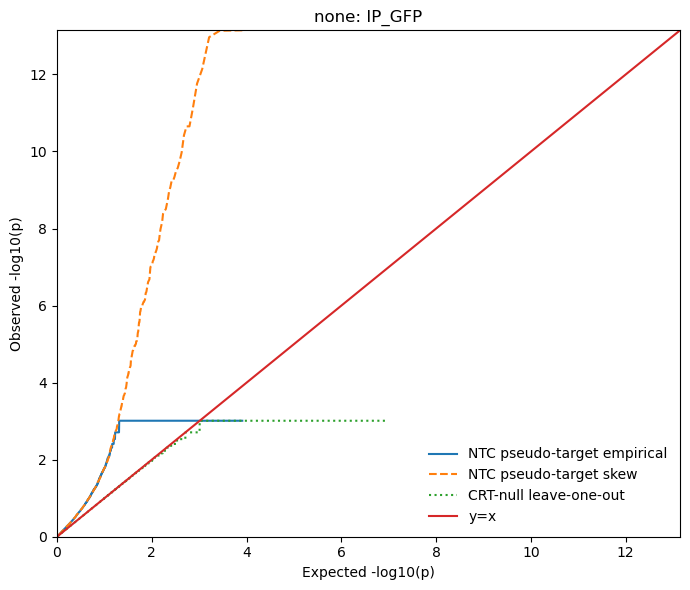

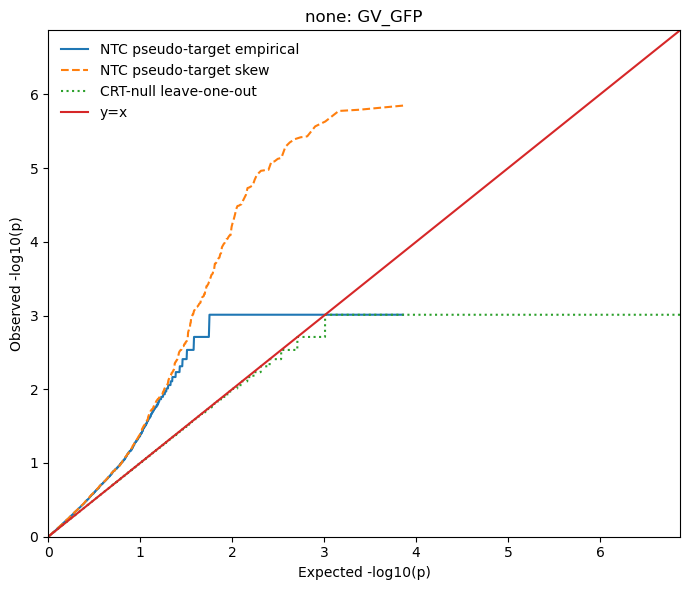

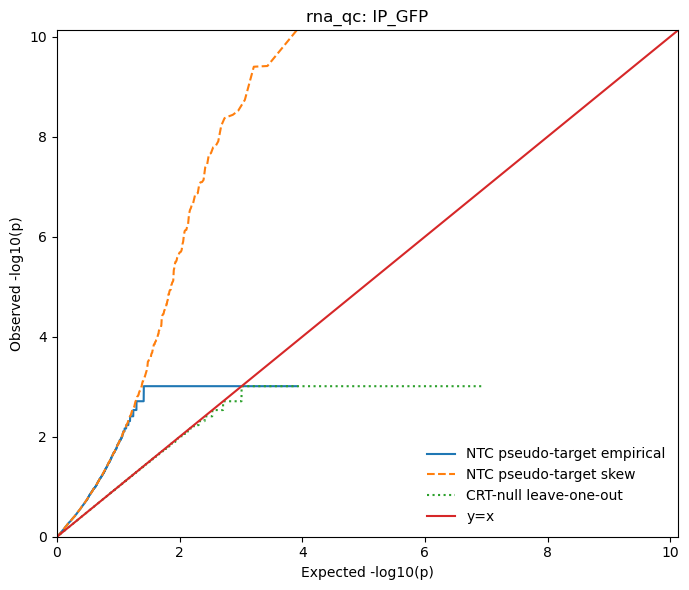

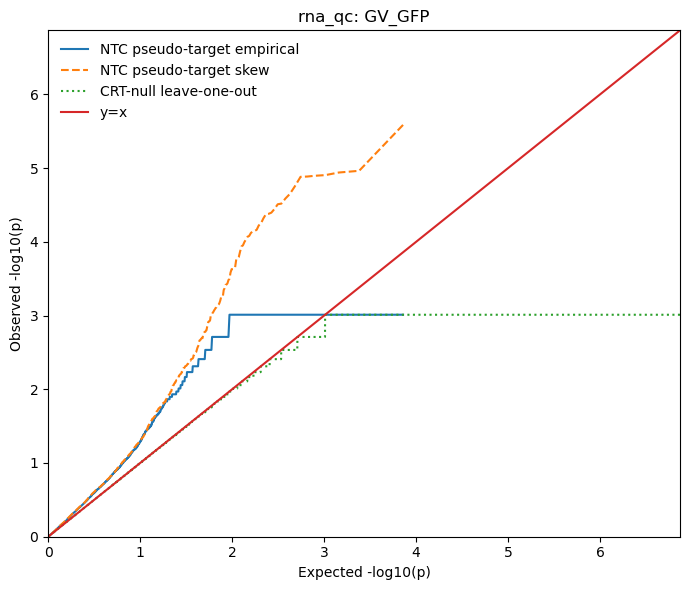

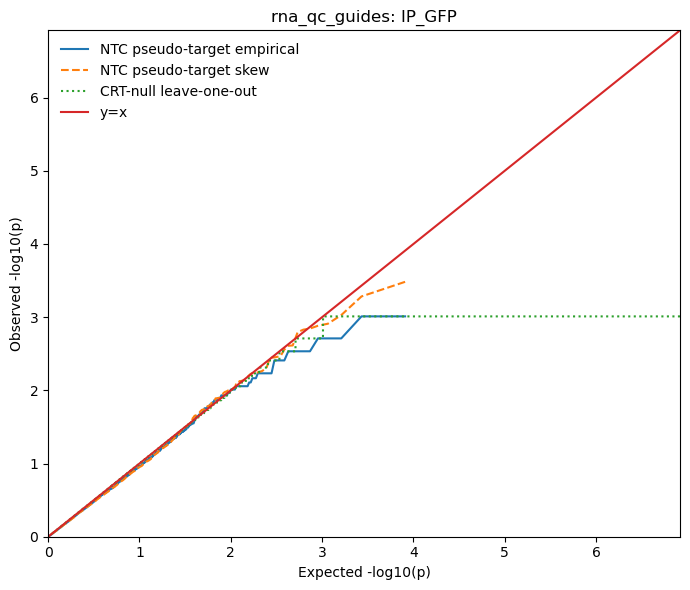

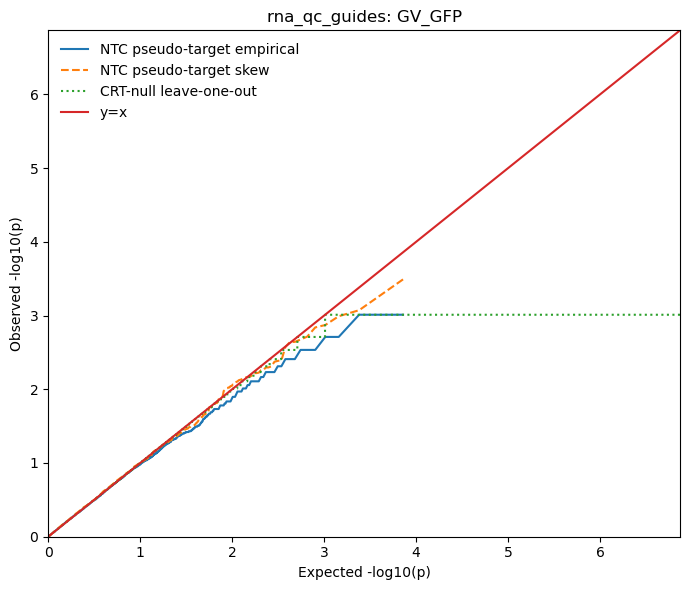

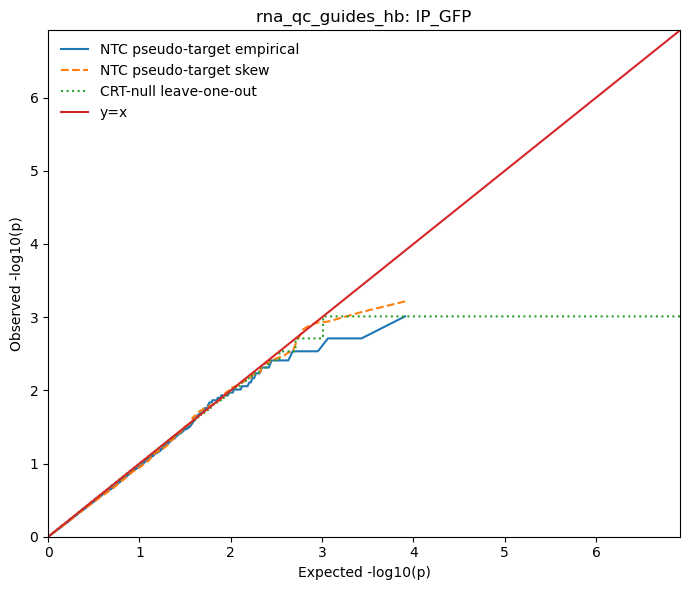

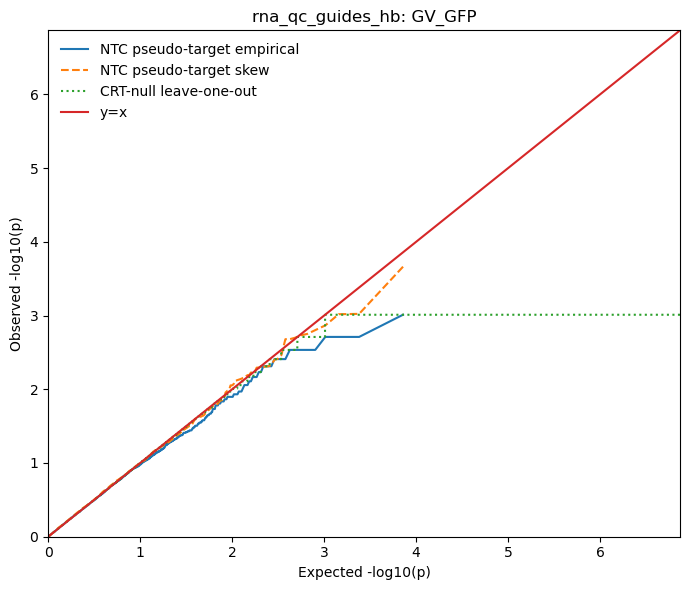

Elapsed minutes: 0.57


In [11]:
RUN_CALIBRATION_GRID = True
OVERWRITE_CALIBRATION = False

conditions = sample_counts.index.astype(str).tolist()
calibration_results: dict[tuple[str, str], CalibrationResult] = {}

if RUN_CALIBRATION_GRID:
    started = time.time()

    for variant_name in COVARIATE_VARIANTS:
        for condition in conditions:
            result = run_ntc_calibration(
                variant_name,
                condition,
                overwrite=OVERWRITE_CALIBRATION,
            )
            calibration_results[
                (variant_name, condition)
            ] = result

            figure, _ = plot_calibration_result(result)
            display(figure)
            plt.close(figure)

    print(
        "Elapsed minutes:",
        round((time.time() - started) / 60, 2),
    )
else:
    print(
        "Calibration is disabled. Set RUN_CALIBRATION_GRID=True "
        "when ready."
    )


## Summarize and compare calibration

In [12]:
# Load all completed calibration results from disk.
calibration_results = {}

for variant_name in COVARIATE_VARIANTS:
    for condition in conditions:
        directory = (
            CALIBRATION_ROOT
            / variant_name
            / safe_name(condition)
        )
        raw_path = directory / "ntc_empirical_pvalues.npy"
        skew_path = directory / "ntc_skew_pvalues.npy"
        null_path = directory / "crt_null_pvalues.npy"

        if raw_path.exists() and null_path.exists():
            calibration_results[
                (variant_name, condition)
            ] = CalibrationResult(
                variant=variant_name,
                condition=condition,
                raw_pvalues=np.load(raw_path),
                skew_pvalues=(
                    np.load(skew_path)
                    if skew_path.exists()
                    else np.empty(0)
                ),
                crt_null_pvalues=np.load(null_path),
                output_dir=directory,
            )

rows = []
for (variant_name, condition), result in calibration_results.items():
    for pvalue_type, values in [
        ("empirical", result.raw_pvalues),
        ("skew", result.skew_pvalues),
        ("crt_null", result.crt_null_pvalues),
    ]:
        if values.size == 0:
            continue
        row = {
            "variant": variant_name,
            "condition": condition,
            "pvalue_type": pvalue_type,
        }
        row.update(calibration_metrics(values))
        rows.append(row)

calibration_summary = pd.DataFrame(rows)

if calibration_summary.empty:
    print(
        "No calibration results found. Run the calibration grid first."
    )
else:
    # Distance is only a sorting aid, not an automatic selection rule.
    calibration_summary["calibration_distance"] = (
        calibration_summary["ks_stat"]
        + (
            calibration_summary["inflation_ratio_0.05"] - 1
        ).abs()
        + (
            calibration_summary["inflation_ratio_0.01"] - 1
        ).abs()
    )

    calibration_summary.to_csv(
        CALIBRATION_ROOT / "calibration_summary.tsv",
        sep="\t",
        index=False,
    )

    display(
        calibration_summary.sort_values(
            [
                "pvalue_type",
                "condition",
                "calibration_distance",
            ]
        )
    )


,variant,condition,pvalue_type,n_pvalues,mean_p,median_p,ks_stat,ks_pvalue,fraction_p_le_0.05,inflation_ratio_0.05,fraction_p_le_0.01,inflation_ratio_0.01,fraction_p_le_0.001,inflation_ratio_0.001,calibration_distance
5,none,GV_GFP,crt_null,3686400,0.500488,0.500488,0.000977,1.766502e-03,0.049805,0.996094,0.009766,0.976562,0.000977,0.976562,0.028320
11,rna_qc,GV_GFP,crt_null,3686400,0.500488,0.500488,0.000977,1.766502e-03,0.049805,0.996094,0.009766,0.976562,0.000977,0.976562,0.028320
17,rna_qc_guides,GV_GFP,crt_null,3686400,0.500488,0.500488,0.000977,1.766502e-03,0.049805,0.996094,0.009766,0.976562,0.000977,0.976562,0.028320
23,rna_qc_guides_hb,GV_GFP,crt_null,3686400,0.500488,0.500488,0.000977,1.766502e-03,0.049805,0.996094,0.009766,0.976562,0.000977,0.976562,0.028320
2,none,IP_GFP,crt_null,4147200,0.500488,0.500488,0.000977,7.335168e-04,0.049805,0.996094,0.009766,0.976562,0.000977,0.976562,0.028320
8,rna_qc,IP_GFP,crt_null,4147200,0.500488,0.500488,0.000977,7.335168e-04,0.049805,0.996094,0.009766,0.976562,0.000977,0.976562,0.028320
14,rna_qc_guides,IP_GFP,crt_null,4147200,0.500488,0.500488,0.000977,7.335168e-04,0.049805,0.996094,0.009766,0.976562,0.000977,0.976562,0.028320
20,rna_qc_guides_hb,IP_GFP,crt_null,4147200,0.500488,0.500488,0.000977,7.335168e-04,0.049805,0.996094,0.009766,0.976562,0.000977,0.976562,0.028320
15,rna_qc_guides,GV_GFP,empirical,3600,0.499764,0.497561,0.010467,8.210704e-01,0.046111,0.922222,0.007778,0.777778,0.000556,0.555556,0.310467
21,rna_qc_guides_hb,GV_GFP,empirical,3600,0.499658,0.498537,0.008598,9.507904e-01,0.044444,0.888889,0.007778,0.777778,0.000278,0.277778,0.341931


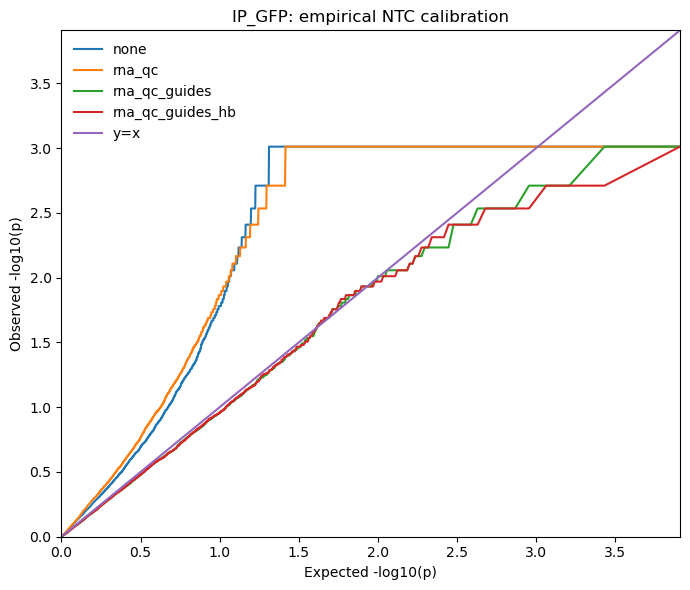

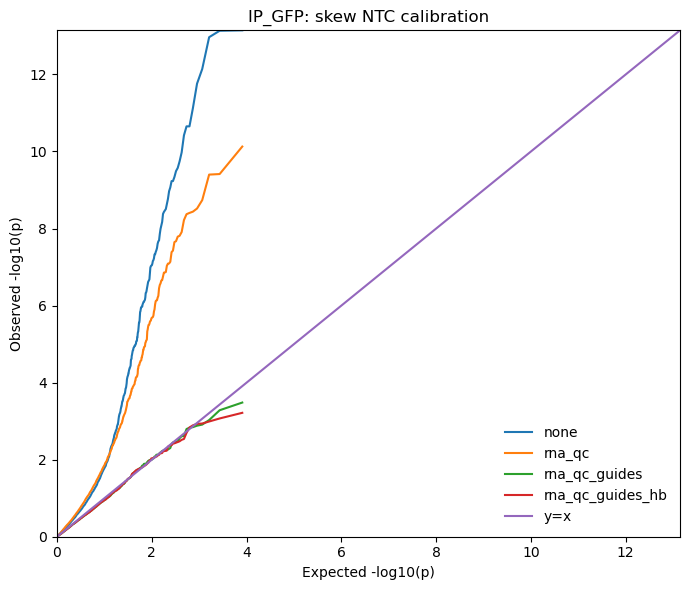

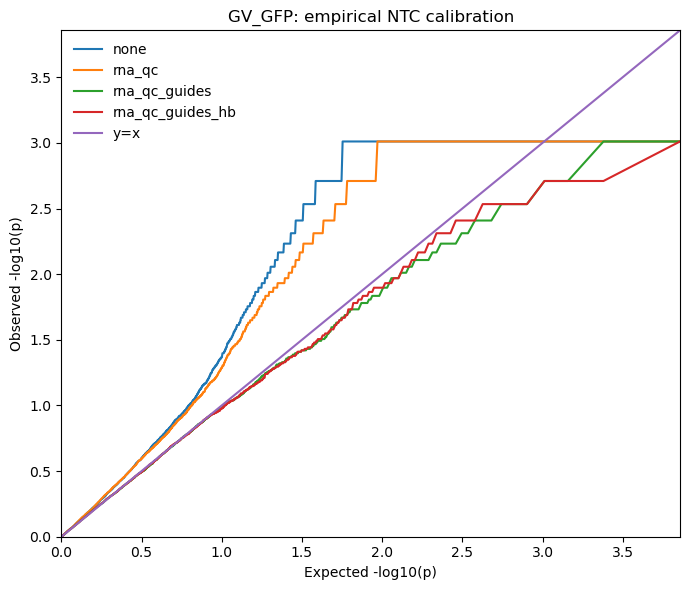

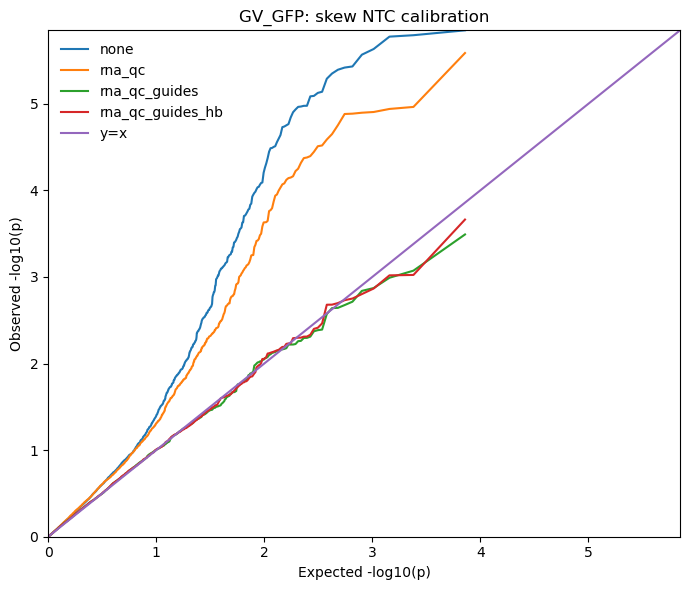

Saved simplified calibration QQ for IP_GFP: 16,200 points
Saved simplified calibration QQ for GV_GFP: 14,400 points


In [13]:
# Overlay candidate variants for each mouse and p-value family.
if not calibration_results:
    print("No calibration results to plot.")
else:
    for condition in conditions:
        for pvalue_type in ["empirical", "skew"]:
            figure, axis = plt.subplots(figsize=(7, 6))
            maxima = [1.0]

            for variant_name in COVARIATE_VARIANTS:
                key = (variant_name, condition)
                if key not in calibration_results:
                    continue

                result = calibration_results[key]
                values = (
                    result.raw_pvalues
                    if pvalue_type == "empirical"
                    else result.skew_pvalues
                )
                x, y = qq_xy(values)
                if x.size == 0:
                    continue

                axis.plot(x, y, label=variant_name)
                maxima.extend([float(x.max()), float(y.max())])

            limit = max(maxima)
            axis.plot([0, limit], [0, limit], label="y=x")
            axis.set_xlim(0, limit)
            axis.set_ylim(0, limit)
            axis.set_xlabel("Expected -log10(p)")
            axis.set_ylabel("Observed -log10(p)")
            axis.set_title(
                f"{condition}: {pvalue_type} NTC calibration"
            )
            axis.legend(frameon=False)
            figure.tight_layout()

            figure.savefig(
                CALIBRATION_ROOT
                / f"compare_{safe_name(condition)}_{pvalue_type}.png",
                dpi=180,
                bbox_inches="tight",
            )
            display(figure)
            plt.close(figure)


# Simplified empirical NTC-only comparison: dark-gray points, no skew curve.
if calibration_results:
    for condition in conditions:
        simple_points = save_simple_calibration_comparison(
            condition,
            calibration_results,
        )
        if not simple_points.empty:
            print(
                f"Saved simplified calibration QQ for {condition}: "
                f"{len(simple_points):,} points"
            )



## Choose the final calibration specification

Guidelines:

- `fraction_p_le_0.05` should be near 0.05;
- `fraction_p_le_0.01` should be near 0.01;
- inflation ratios substantially above 1 indicate anti-conservative p-values;
- values substantially below 1 indicate conservative/deflated p-values;
- prefer a simpler covariate set when calibration is similar;
- verify calibration in **both mice**.

The default below is a starting point, not an automatic conclusion.


In [14]:
SELECTED_VARIANT = "rna_qc_guides"
PRIMARY_PVALUE = "skew"  # "skew" or "empirical"

if SELECTED_VARIANT not in COVARIATE_VARIANTS:
    raise KeyError(SELECTED_VARIANT)
if PRIMARY_PVALUE not in {"skew", "empirical"}:
    raise ValueError(PRIMARY_PVALUE)

print("Selected variant:", SELECTED_VARIANT)
print("Specification:", COVARIATE_VARIANTS[SELECTED_VARIANT])
print("Primary p-value:", PRIMARY_PVALUE)

if not calibration_summary.empty:
    display(
        calibration_summary.loc[
            calibration_summary["variant"]
            == SELECTED_VARIANT
        ].sort_values(["condition", "pvalue_type"])
    )


Selected variant: rna_qc_guides
Specification: {'covariates': ['pct_counts_mt', 'pct_counts_ribo'], 'log_covariates': ['total_counts', 'n_genes_by_counts', 'n_assigned_guides', 'total_guide_umis']}
Primary p-value: skew


,variant,condition,pvalue_type,n_pvalues,mean_p,median_p,ks_stat,ks_pvalue,fraction_p_le_0.05,inflation_ratio_0.05,fraction_p_le_0.01,inflation_ratio_0.01,fraction_p_le_0.001,inflation_ratio_0.001,calibration_distance
17,rna_qc_guides,GV_GFP,crt_null,3686400,0.500488,0.500488,0.000977,0.001767,0.049805,0.996094,0.009766,0.976562,0.000977,0.976562,0.028320
15,rna_qc_guides,GV_GFP,empirical,3600,0.499764,0.497561,0.010467,0.821070,0.046111,0.922222,0.007778,0.777778,0.000556,0.555556,0.310467
16,rna_qc_guides,GV_GFP,skew,3600,0.494344,0.487297,0.016125,0.303262,0.047778,0.955556,0.011667,1.166667,0.000556,0.555556,0.227236
14,rna_qc_guides,IP_GFP,crt_null,4147200,0.500488,0.500488,0.000977,0.000734,0.049805,0.996094,0.009766,0.976562,0.000977,0.976562,0.028320
12,rna_qc_guides,IP_GFP,empirical,4050,0.513006,0.516098,0.021722,0.043127,0.045926,0.918519,0.010123,1.012346,0.000494,0.493827,0.115550
13,rna_qc_guides,IP_GFP,skew,4050,0.514084,0.517813,0.024137,0.017560,0.044938,0.898765,0.010123,1.012346,0.000741,0.740741,0.137717


## Full target–program CRT

In [15]:
def long_results_table(
    out: dict[str, Any],
    *,
    condition: str,
    primary_pvalue: str,
) -> pd.DataFrame:
    empirical = out["pvals_raw_df"]

    skew = out.get("pvals_df")
    if skew is None:
        skew = out.get("pvals_skew_df")

    beta = out["betas_df"]

    def melt(frame: pd.DataFrame, value_name: str):
        index_name = frame.index.name or "target_name"
        current = frame.copy()
        current.index.name = "target_name"
        return (
            current.reset_index()
            .melt(
                id_vars="target_name",
                var_name="program_name",
                value_name=value_name,
            )
        )

    table = melt(empirical, "p_empirical").merge(
        melt(beta, "beta_clr"),
        on=["target_name", "program_name"],
        how="inner",
    )

    if skew is not None:
        table = table.merge(
            melt(skew, "p_skew"),
            on=["target_name", "program_name"],
            how="left",
        )
    else:
        table["p_skew"] = np.nan

    table["q_empirical_BH"] = multipletests(
        table["p_empirical"].fillna(1.0),
        method="fdr_bh",
    )[1]

    if table["p_skew"].notna().any():
        table["q_skew_BH"] = multipletests(
            table["p_skew"].fillna(1.0),
            method="fdr_bh",
        )[1]
    else:
        table["q_skew_BH"] = np.nan

    # beta_clr is a CLR log-ratio effect, not an ordinary expression log2FC.
    table["approx_relative_log2fc"] = (
        (K / (K - 1))
        * table["beta_clr"]
        / np.log(2)
    )

    table["condition"] = condition
    table["primary_pvalue_type"] = primary_pvalue

    if primary_pvalue == "skew":
        table["primary_pvalue"] = table["p_skew"]
        table["primary_q_BH"] = table["q_skew_BH"]
    else:
        table["primary_pvalue"] = table["p_empirical"]
        table["primary_q_BH"] = table["q_empirical_BH"]

    return table


def signed_stouffer_two_mouse(
    table_a: pd.DataFrame,
    table_b: pd.DataFrame,
) -> pd.DataFrame:
    key = ["target_name", "program_name"]

    left = table_a[
        key + ["beta_clr", "primary_pvalue", "primary_q_BH"]
    ].rename(
        columns={
            "beta_clr": "beta_IP_GFP",
            "primary_pvalue": "p_IP_GFP",
            "primary_q_BH": "q_IP_GFP",
        }
    )
    right = table_b[
        key + ["beta_clr", "primary_pvalue", "primary_q_BH"]
    ].rename(
        columns={
            "beta_clr": "beta_GV_GFP",
            "primary_pvalue": "p_GV_GFP",
            "primary_q_BH": "q_GV_GFP",
        }
    )

    merged = left.merge(right, on=key, how="inner")
    merged["same_sign"] = (
        np.sign(merged["beta_IP_GFP"])
        == np.sign(merged["beta_GV_GFP"])
    )

    p_ip = merged["p_IP_GFP"].clip(1e-300, 1.0)
    p_gv = merged["p_GV_GFP"].clip(1e-300, 1.0)

    z_ip = np.sign(merged["beta_IP_GFP"]) * norm.isf(
        p_ip / 2
    )
    z_gv = np.sign(merged["beta_GV_GFP"]) * norm.isf(
        p_gv / 2
    )
    z_combined = (z_ip + z_gv) / math.sqrt(2)

    merged["signed_stouffer_z"] = z_combined
    merged["signed_stouffer_p"] = (
        2 * norm.sf(np.abs(z_combined))
    )
    merged["signed_stouffer_q_BH"] = multipletests(
        merged["signed_stouffer_p"],
        method="fdr_bh",
    )[1]
    return merged


def run_full_crt_for_condition(
    condition: str,
    *,
    variant_name: str,
    B: int,
    primary_pvalue: str,
    overwrite: bool = False,
) -> tuple[pd.DataFrame, dict[str, Any]]:
    specification = COVARIATE_VARIANTS[variant_name]
    output_dir = (
        DISCOVERY_ROOT
        / variant_name
        / safe_name(condition)
    )
    output_dir.mkdir(parents=True, exist_ok=True)

    table_path = output_dir / "target_program_CRT.tsv"
    if table_path.exists() and not overwrite:
        cached_table = pd.read_csv(table_path, sep="\t")
        ensure_cached_discovery_simple_qq(
            table=cached_table,
            output_dir=output_dir,
            variant_name=variant_name,
            condition=condition,
        )
        return cached_table, {}

    adata = build_crt_adata(
        specification["covariates"],
        specification["log_covariates"],
    )
    adata_condition = condition_subset(adata, condition)
    inputs = prepare_inputs(adata_condition)

    print(
        f"Running full CRT for {condition}: "
        f"{adata_condition.n_obs:,} cells, B={B:,}"
    )

    out = run_all_genes_union_crt(
        inputs=inputs,
        B=B,
        n_jobs=N_JOBS,
        calibrate_skew_normal=True,
        return_raw_pvals=True,
        return_skew_normal=True,
    )

    # Recreate matched NTC pseudo-targets for the final QQ plot.
    (
        ntc_guides,
        guide_frequency,
        guide_to_bin,
        real_gene_bin_signatures,
    ) = build_ntc_group_inputs(
        inputs=inputs,
        ntc_label=CONTROL_TARGET_LABELS,
        group_size=GUIDES_PER_PSEUDO_TARGET,
        n_bins=NTC_FREQUENCY_BINS,
    )
    groups = make_ntc_groups_ensemble(
        ntc_guides=ntc_guides,
        ntc_freq=guide_frequency,
        real_gene_bin_sigs=real_gene_bin_signatures,
        guide_to_bin=guide_to_bin,
        n_ensemble=NTC_ENSEMBLES,
        seed0=NTC_GROUP_SEED,
        group_size=GUIDES_PER_PSEUDO_TARGET,
        max_groups=NTC_MAX_GROUPS,
    )

    ntc_empirical = crt_pvals_for_ntc_groups_ensemble(
        inputs=inputs,
        ntc_groups_ens=groups,
        B=B,
        seed0=NTC_CRT_SEED,
    )
    ntc_skew = crt_pvals_for_ntc_groups_ensemble_skew(
        inputs=inputs,
        ntc_groups_ens=groups,
        B=B,
        seed0=NTC_CRT_SEED,
    )

    # Save the exact discovery-run NTC p-values for plotting/replotting.
    save_ntc_frames(
        ntc_empirical,
        output_dir / "ntc_empirical_pvalues_wide.tsv",
    )
    save_ntc_frames(
        ntc_skew,
        output_dir / "ntc_skew_pvalues_wide.tsv",
    )
    np.save(
        output_dir / "ntc_empirical_pvalues.npy",
        flatten_ntc_frames(ntc_empirical),
    )

    guide_to_column = {
        guide: index
        for index, guide in enumerate(inputs.guide_names)
    }
    null_pvalues = np.concatenate(
        [
            compute_guide_set_null_pvals(
                guide_idx=[
                    guide_to_column[guide]
                    for guide in guides
                ],
                inputs=inputs,
                B=B,
            ).ravel()
            for ensemble_groups in groups
            for guides in ensemble_groups.values()
        ]
    )

    skew_frame = out.get("pvals_df")
    if skew_frame is None:
        skew_frame = out.get("pvals_skew_df")

    axis = qq_plot_ntc_pvals(
        pvals_raw_df=out["pvals_raw_df"],
        guide2gene=adata_condition.uns["guide2gene"],
        ntc_genes=CONTROL_TARGET_LABELS,
        pvals_skew_df=skew_frame,
        null_pvals=null_pvalues,
        ntc_group_pvals_ens=ntc_empirical,
        ntc_group_pvals_skew_ens=ntc_skew,
        show_ntc_ensemble_band=True,
        show_all_pvals=True,
        title=f"K30, dt2.0 CRT calibration: {condition}",
    )
    figure = axis.figure
    figure.tight_layout()
    figure.savefig(
        output_dir / "CRT_calibration_QQ.png",
        dpi=180,
        bbox_inches="tight",
    )
    display(figure)
    plt.close(figure)

    # Simplified point-only QQ: real empirical target p-values versus
    # empirical NTC pseudo-target p-values. No skew-fit curve is shown.
    real_qq_points = qq_points_from_real_pvalue_frame(
        out["pvals_raw_df"],
        source="Full-discovery real-target empirical p-values",
    )
    ntc_qq_points = qq_points_from_ntc_frames(
        ntc_empirical,
        source="Discovery-run NTC empirical p-values",
    )
    real_qq_points["variant"] = variant_name
    real_qq_points["condition"] = condition
    ntc_qq_points["variant"] = variant_name
    ntc_qq_points["condition"] = condition
    save_simple_qq_plot(
        output_stem=output_dir / "CRT_calibration_QQ_simple",
        title=f"K30, dt2.0 empirical CRT QQ: {condition}",
        real_points=real_qq_points,
        ntc_points=ntc_qq_points,
    )

    table = long_results_table(
        out,
        condition=condition,
        primary_pvalue=primary_pvalue,
    )
    table.to_csv(table_path, sep="\t", index=False)

    metadata = {
        "K": K,
        "density_threshold": DENSITY_THRESHOLD,
        "condition": condition,
        "variant": variant_name,
        "covariates": specification["covariates"],
        "log_covariates": specification["log_covariates"],
        "B": B,
        "n_jobs": N_JOBS,
        "primary_pvalue": primary_pvalue,
        "effect_scale": "CLR log-ratio beta",
    }
    (output_dir / "config.json").write_text(
        json.dumps(metadata, indent=2) + "\n"
    )
    return table, out


### Execute the full run

Set `RUN_FULL_DISCOVERY = True` only after reviewing the calibration grid and setting `SELECTED_VARIANT` and `PRIMARY_PVALUE`.

The production default is 5,000 permutations. This can be computationally intensive in an interactive Jupyter session; use a sufficiently large Sherlock Jupyter allocation.


In [16]:
RUN_FULL_DISCOVERY = True
OVERWRITE_DISCOVERY = False

discovery_tables: dict[str, pd.DataFrame] = {}

if RUN_FULL_DISCOVERY:
    started = time.time()

    for condition in conditions:
        table, _ = run_full_crt_for_condition(
            condition,
            variant_name=SELECTED_VARIANT,
            B=DISCOVERY_B,
            primary_pvalue=PRIMARY_PVALUE,
            overwrite=OVERWRITE_DISCOVERY,
        )
        discovery_tables[condition] = table
        display(
            table.sort_values("primary_q_BH").head(20)
        )

    print(
        "Elapsed minutes:",
        round((time.time() - started) / 60, 2),
    )
else:
    print(
        "Full discovery is disabled. Set RUN_FULL_DISCOVERY=True "
        "after selecting the calibration specification."
    )


,target_name,program_name,p_empirical,beta_clr,p_skew,q_empirical_BH,q_skew_BH,approx_relative_log2fc,condition,primary_pvalue_type,primary_pvalue,primary_q_BH
77,Kdr,5,0.000200,1.414975,0.000085,0.033993,0.021787,2.111770,IP_GFP,skew,0.000085,0.021787
28,Smad4,2,0.000200,-1.435775,0.000049,0.033993,0.021787,-2.142812,IP_GFP,skew,0.000049,0.021787
146,Notch1,9,0.000200,-1.518763,0.000349,0.033993,0.059312,-2.266667,IP_GFP,skew,0.000349,0.059312
348,Kcnk3,21,0.001600,-1.187703,0.000594,0.203959,0.075795,-1.772580,IP_GFP,skew,0.000594,0.075795
120,Atp13a3,8,0.002999,-1.088562,0.002660,0.254949,0.237831,-1.624617,IP_GFP,skew,0.002660,0.237831
132,Sox17,8,0.002000,-1.456698,0.002798,0.203959,0.237831,-2.174039,IP_GFP,skew,0.002798,0.237831
141,Eif2ak4,9,0.006599,1.235948,0.004149,0.305939,0.264478,1.844583,IP_GFP,skew,0.004149,0.264478
459,Acvrl1,28,0.004199,1.215362,0.004129,0.267696,0.264478,1.813858,IP_GFP,skew,0.004129,0.264478
27,Notch1,2,0.005199,-1.014715,0.004902,0.294608,0.277790,-1.514405,IP_GFP,skew,0.004902,0.277790
503,Notch1,30,0.004199,0.933932,0.005567,0.267696,0.283906,1.393840,IP_GFP,skew,0.005567,0.283906


,target_name,program_name,p_empirical,beta_clr,p_skew,q_empirical_BH,q_skew_BH,approx_relative_log2fc,condition,primary_pvalue_type,primary_pvalue,primary_q_BH
348,Kcnk3,21,0.002000,-1.922923,0.001264,0.790342,0.644685,-2.869853,GV_GFP,skew,0.001264,0.644685
48,Tbx4,3,0.013197,-1.412683,0.020890,0.790342,0.801391,-2.108349,GV_GFP,skew,0.020890,0.801391
409,Atp13a3,25,0.026395,1.093609,0.030906,0.803599,0.801391,1.632149,GV_GFP,skew,0.030906,0.801391
338,Trp53,20,0.015397,-1.951276,0.006709,0.790342,0.801391,-2.912169,GV_GFP,skew,0.006709,0.801391
268,Sox17,16,0.007998,2.051879,0.010103,0.790342,0.801391,3.062313,GV_GFP,skew,0.010103,0.801391
272,Acvrl1,17,0.033193,-1.768372,0.031964,0.803599,0.801391,-2.639195,GV_GFP,skew,0.031964,0.801391
347,Gdf2,21,0.039392,-1.628247,0.026012,0.803599,0.801391,-2.430066,GV_GFP,skew,0.026012,0.801391
393,Bmpr2,24,0.032194,1.597395,0.034570,0.803599,0.801391,2.384022,GV_GFP,skew,0.034570,0.801391
279,Gdf2,17,0.031194,1.722615,0.028197,0.803599,0.801391,2.570904,GV_GFP,skew,0.028197,0.801391
237,non-targeting,14,0.018596,-0.970403,0.019378,0.790342,0.801391,-1.448271,GV_GFP,skew,0.019378,0.801391


Elapsed minutes: 0.01


## Cross-mouse summary

In [17]:
# Load completed per-mouse tables from disk.
discovery_tables = {}

for condition in conditions:
    path = (
        DISCOVERY_ROOT
        / SELECTED_VARIANT
        / safe_name(condition)
        / "target_program_CRT.tsv"
    )
    if path.exists():
        discovery_tables[condition] = pd.read_csv(
            path,
            sep="\t",
        )

if {"IP_GFP", "GV_GFP"}.issubset(discovery_tables):
    cross_mouse = signed_stouffer_two_mouse(
        discovery_tables["IP_GFP"],
        discovery_tables["GV_GFP"],
    )
    cross_mouse.to_csv(
        DISCOVERY_ROOT
        / SELECTED_VARIANT
        / "cross_mouse_target_program_summary.tsv",
        sep="\t",
        index=False,
    )

    display(
        cross_mouse.sort_values(
            "signed_stouffer_q_BH"
        ).head(30)
    )

    print(
        "Same-sign fraction:",
        float(cross_mouse["same_sign"].mean()),
    )
else:
    print(
        "Both per-mouse discovery tables are required before "
        "creating the cross-mouse summary."
    )


,target_name,program_name,beta_IP_GFP,p_IP_GFP,q_IP_GFP,beta_GV_GFP,p_GV_GFP,q_GV_GFP,same_sign,signed_stouffer_z,signed_stouffer_p,signed_stouffer_q_BH
348,Kcnk3,21,-1.187703,0.000594,0.075795,-1.922923,0.001264,0.644685,True,-4.708013,0.000003,0.001276
146,Notch1,9,-1.518763,0.000349,0.059312,-0.944759,0.154500,0.878319,True,-3.535402,0.000407,0.103825
338,Trp53,20,-0.857691,0.055520,0.643523,-1.951276,0.006709,0.801391,True,-3.270878,0.001072,0.182264
423,Trp53,25,-0.859412,0.044762,0.605575,-1.230048,0.054258,0.849658,True,-2.780103,0.005434,0.346428
209,Eif2ak4,13,-1.147002,0.010057,0.415865,-0.956724,0.109869,0.878319,True,-2.950506,0.003173,0.346428
28,Smad4,2,-1.435775,0.000049,0.021787,0.106286,0.912639,0.975440,False,-2.795177,0.005187,0.346428
141,Eif2ak4,9,1.235948,0.004149,0.264478,0.753258,0.270285,0.883623,True,2.806533,0.005008,0.346428
274,Bmpr2,17,0.755403,0.081705,0.693913,1.745996,0.016675,0.801391,True,2.923662,0.003459,0.346428
73,Eif2ak4,5,0.866946,0.020545,0.423077,0.572211,0.217847,0.878319,True,2.509182,0.012101,0.381581
77,Kdr,5,1.414975,0.000085,0.021787,-0.147726,0.735712,0.975440,False,2.539269,0.011108,0.381581


Same-sign fraction: 0.5235294117647059


## Consolidate simplified QQ data

Each simplified QQ plot has its own `*_points.csv`. This cell also creates one combined CSV and a manifest so every plot can be regenerated without parsing figures.


In [18]:
simple_qq_csvs = sorted(
    path
    for path in CRT_ROOT.rglob("*_simple_points.csv")
    if QQ_EXPORT_ROOT not in path.parents
)

manifest_rows = []
combined_frames = []

for path in simple_qq_csvs:
    current = pd.read_csv(path)
    relative_path = path.relative_to(CRT_ROOT)
    current.insert(0, "source_csv", str(relative_path))
    combined_frames.append(current)
    manifest_rows.append(
        {
            "source_csv": str(relative_path),
            "n_rows": int(len(current)),
            "series": ";".join(
                sorted(current.get("series", pd.Series(dtype=str)).dropna().astype(str).unique())
            ),
        }
    )

if combined_frames:
    all_simple_qq_points = pd.concat(
        combined_frames,
        ignore_index=True,
        sort=False,
    )
    combined_path = QQ_EXPORT_ROOT / "all_simple_QQ_points.csv"
    all_simple_qq_points.to_csv(combined_path, index=False)

    manifest = pd.DataFrame(manifest_rows)
    manifest_path = QQ_EXPORT_ROOT / "simple_QQ_manifest.csv"
    manifest.to_csv(manifest_path, index=False)

    print("Combined simple QQ data:", combined_path)
    print("QQ manifest:", manifest_path)
    display(manifest)
else:
    print(
        "No simplified QQ CSVs were found yet. Run the calibration and/or "
        "discovery cells first."
    )


Combined simple QQ data: /oak/stanford/groups/engreitz/Users/tri/10xPerturbSeq/analysis/250507_ePAH1_NovaSeq/CRISPR_count/IP_GV_unified_sceptre_cnmf_no_celltype/PerturbNMF/results/IP_GV_skcnmf_K30_dt2_0_n100/Evaluation/30_2_0/CRT_notebook/simple_QQ_exports/all_simple_QQ_points.csv
QQ manifest: /oak/stanford/groups/engreitz/Users/tri/10xPerturbSeq/analysis/250507_ePAH1_NovaSeq/CRISPR_count/IP_GV_unified_sceptre_cnmf_no_celltype/PerturbNMF/results/IP_GV_skcnmf_K30_dt2_0_n100/Evaluation/30_2_0/CRT_notebook/simple_QQ_exports/simple_QQ_manifest.csv


,source_csv,n_rows,series
0,calibration/compare_GV_GFP_empirical_simple_po...,14400,NTC pseudo-targets
1,calibration/compare_IP_GFP_empirical_simple_po...,16200,NTC pseudo-targets
2,calibration/none/GV_GFP/calibration_qq_simple_...,3600,NTC pseudo-targets
3,calibration/none/IP_GFP/calibration_qq_simple_...,4050,NTC pseudo-targets
4,calibration/rna_qc/GV_GFP/calibration_qq_simpl...,3600,NTC pseudo-targets
5,calibration/rna_qc/IP_GFP/calibration_qq_simpl...,4050,NTC pseudo-targets
6,calibration/rna_qc_guides/GV_GFP/calibration_q...,3600,NTC pseudo-targets
7,calibration/rna_qc_guides/IP_GFP/calibration_q...,4050,NTC pseudo-targets
8,calibration/rna_qc_guides_hb/GV_GFP/calibratio...,3600,NTC pseudo-targets
9,calibration/rna_qc_guides_hb/IP_GFP/calibratio...,4050,NTC pseudo-targets


## Interpretation notes

- The CRT coefficient is a **CLR log-ratio effect**, not a conventional gene-expression log2 fold change.
- Empirical and skew-calibrated p-values are both retained.
- BH correction is applied within each mouse across all target–program tests.
- The signed-Stouffer table is an exploratory two-mouse summary. With only two biological replicates, it should not be treated as a substitute for a larger replicate-level analysis.
- Because this is a high-MOI experiment, inspect NTC calibration, guide burden, and cross-mouse direction consistency before prioritizing associations.

- Knockdown CSVs use pseudobulk CPM. The primary high-MOI reference contains cells with an NTC guide and excludes the tested target while allowing other targets; the strict NTC-only version is retained as a sensitivity analysis.
- Simplified QQ plots use empirical p-values only: real targets are dark blue, NTC pseudo-targets are dark gray points, and no skew-fit curve is shown.

- `target_gene_KD_NTC_target_excluded_equal_mouse_summary.csv` combines the two mouse-specific log2 CPM ratios with equal mouse weight; it is preferable to the cell-count-weighted `ALL_pooled` row for a single summary value.